# Dynamic Connectome-Based Early Warning of Sleep-Deprivation-Induced Attentional Failure via Instability-Regularized Graph Attention Networks

**Dataset:** OpenNeuro ds000201, Stockholm SleepyBrain Project (approximately 48 participants; rested versus sleep-deprived crossover; resting-state fMRI and task-PVT).

## Phase 1 - Data Preparation

1. Mount Google Drive and inventory the dataset files.
2. Install and run fMRIPrep on resting-state and anatomical scans for motion correction, registration, and confound estimation.
3. Denoise by regressing motion parameters and aCompCor components, applying a high-pass filter, and scrubbing high-framewise-displacement volumes.
4. Parcellate with Schaefer-400 (primary) and AAL-116 (robustness check), then extract ROI time series per participant and session.

**Expected result:** clean, denoised ROI time-series matrices (ROIs x timepoints) for every participant and both sessions. This is the validated data foundation.

## Phase 2 - PVT Lapse Labeling

1. Parse `_events.tsv` files from task-PVT runs.
2. Define a lapse as reaction time greater than 500 ms or a missed response.
3. Build a time-aligned lapse timeline for every participant/session.

**Expected result:** a ground-truth event log describing attentional failures in each session, used as supervision for forecasting and the instability-alignment loss.

## Phase 3 - Dynamic Connectome Construction

1. Compute sliding-window functional connectivity over resting-state time series (approximately 30-60 s windows, one-TR steps).
2. Build a graph sequence per session: nodes are ROIs and edges are thresholded/sparsified windowed FC.
3. Use regional time-series statistics as node features, including mean, variance, and spectral power.

**Expected result:** a temporal sequence of connectivity graphs per session, forming the GAT input.

## Phase 4 - Baseline Model

1. Implement a standard PyTorch Geometric GAT to classify rested versus sleep-deprived from one graph snapshot.
2. Extend it to a sequence model (GAT plus GRU or temporal pooling) that forecasts an upcoming lapse from window *t* to lapse at *t + k*.
3. Compare against static-FC plus SVM, a plain GCN, and LSTM-on-FC-vectors baselines.

**Expected result:** a working forecasting pipeline with baseline performance, such as AUROC for whether a lapse occurs in the next *k* seconds. This is independently a legitimate MSc-level result.

## Phase 5 - Core Contribution: Instability-Alignment Loss

1. Define the Attention Instability Index (AII): variance or entropy of GAT attention weights on PFC-to-sensory edges across consecutive windows.
2. Add an auxiliary loss that supervises AII to rise before labeled lapse events.
3. Optimize: forecasting loss + lambda x instability-alignment loss.
4. Ablate lambda = 0 versus lambda > 0, comparing forecasting accuracy and AII predictive lead time before lapses.

**Expected result:** evidence that the joint objective improves forecasting and that AII rises measurably before behavioral lapses: an interpretable, trainable early-warning biomarker rather than only a black-box classifier.

## Phase 6 - Validation Rigor

1. Use nested leave-subject-out cross-validation; never split within participant.
2. Run permutation testing by shuffling labels and rebuilding the null distribution.
3. Repeat Phases 3-5 with AAL-116 to test that results are not atlas artifacts.

**Expected result:** statistically defensible results appropriate for a small sample (approximately N = 48).

## Phase 7 - Interpretation and Writing

1. Identify PFC-sensory edges consistently flagged as unstable before lapses.
2. Compare them qualitatively with edges reported in psychosis-risk and reality-monitoring connectome literature.
3. Write the manuscript: Introduction (corollary-discharge/reality-monitoring framing), Methods (Phases 1-5), Results (Phase 4-6 metrics), and Discussion (translational relevance, N = 48 limitation, and proxy-label limitation).

**Expected result:** a complete manuscript that makes a focused claim about fatigue/PVT-lapse forecasting, frames the work toward reality-monitoring relevance without claiming to measure it directly, and presents the instability-alignment loss and AII biomarker as the central contribution.

## Step 1 - Required Drive Inventory

Run the next cell in Google Colab before proceeding. It mounts Drive, locates likely dataset roots, and reports whether task `_events.tsv` files exist.

## Step 1 - Mount and Inventory Google Drive

Mount the Google Drive containing the OpenNeuro download, discover BIDS dataset roots, and enumerate event files. The output establishes the exact dataset path and confirms whether PVT event logs are available before any preprocessing or modeling begins.

In [1]:
# STEP 1: Run this cell in Google Colab and paste its complete output back into the chat.
# Before mounting: open the shared-folder link, then use Organize > Add shortcut > My Drive.
from google.colab import drive
from pathlib import Path

MOUNT_POINT = '/content/drive'
try:
    drive.mount(MOUNT_POINT, force_remount=True, timeout_ms=180_000)
except ValueError as error:
    print(f'DRIVE MOUNT FAILED: {error}')
    print('Fix: Runtime > Disconnect and delete runtime, reconnect, then rerun this cell.')
    print('Also allow pop-ups and third-party cookies for colab.research.google.com and accounts.google.com.')
    print('Confirm that Colab is signed into the Google account that can open the shared-folder link.')
    raise

drive_root = Path(f'{MOUNT_POINT}/MyDrive')
print(f'Drive root: {drive_root}')
print(f'Drive root exists: {drive_root.exists()}')

# Locate likely BIDS/ds000201 dataset roots without assuming the Drive folder name.
candidates = []
for marker in ('dataset_description.json', 'participants.tsv'):
    candidates.extend(path.parent for path in drive_root.rglob(marker))
dataset_roots = sorted(set(candidates))

print('\nCandidate dataset root(s):')
if dataset_roots:
    for root in dataset_roots:
        print(f'  {root}')
else:
    print('  None found')

events_files = sorted(drive_root.rglob('*_events.tsv'))
pvt_events = [path for path in events_files if 'pvt' in path.name.lower() or 'pvt' in str(path).lower()]

print(f'\nAll _events.tsv files found: {len(events_files)}')
for path in events_files:
    print(f'  {path}')

print(f'\nPVT-related _events.tsv files found: {len(pvt_events)}')
for path in pvt_events:
    print(f'  {path}')

print('\nSTEP 1 SUMMARY')
print(f'Exact Drive path scanned: {drive_root}')
print(f'_events.tsv files exist: {bool(events_files)}')
print(f'PVT-related _events.tsv files exist: {bool(pvt_events)}')


Mounted at /content/drive
Drive root: /content/drive/MyDrive
Drive root exists: True

Candidate dataset root(s):
  /content/drive/MyDrive/sem 4 project (1)/ds000201-download

All _events.tsv files found: 930
  /content/drive/MyDrive/sem 4 project (1)/ds000201-download/sub-9001/ses-1/beh/sub-9001_ses-1_task-PVT_events.tsv
  /content/drive/MyDrive/sem 4 project (1)/ds000201-download/sub-9001/ses-1/func/sub-9001_ses-1_task-arrows_events.tsv
  /content/drive/MyDrive/sem 4 project (1)/ds000201-download/sub-9001/ses-1/func/sub-9001_ses-1_task-faces_events.tsv
  /content/drive/MyDrive/sem 4 project (1)/ds000201-download/sub-9001/ses-1/func/sub-9001_ses-1_task-hands_events.tsv
  /content/drive/MyDrive/sem 4 project (1)/ds000201-download/sub-9001/ses-1/func/sub-9001_ses-1_task-sleepiness_events.tsv
  /content/drive/MyDrive/sem 4 project (1)/ds000201-download/sub-9001/ses-2/beh/sub-9001_ses-2_task-PVT_events.tsv
  /content/drive/MyDrive/sem 4 project (1)/ds000201-download/sub-9001/ses-2/func/sub

## Step 2 - Inspect a PVT Event File

Read one known PVT BIDS event file and print its columns, data types, rows, and numerical summaries. This confirms the reaction-time field, missed-response encoding, and measurement units before implementing lapse labeling.

In [2]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

sample_pvt = drive_root / 'sub-9001' / 'ses-1' / 'beh' / 'sub-9001_ses-1_task-PVT_events.tsv'
df = pd.read_csv(sample_pvt, sep='\t')

print("Columns:", list(df.columns))
print("Shape:", df.shape)
print("\nFirst 15 rows:")
print(df.head(15).to_string())
print("\nColumn dtypes:")
print(df.dtypes)
print("\nSummary stats (numeric columns):")
print(df.describe())


Columns: ['onset', 'duration', 'response_time']
Shape: (92, 3)

First 15 rows:
    onset  duration  response_time
0    12.7       NaN            NaN
1     NaN       NaN          0.395
2    16.0       NaN            NaN
3     NaN       NaN          0.331
4    23.9       NaN            NaN
5     NaN       NaN          0.195
6    27.8       NaN            NaN
7     NaN       NaN          0.229
8    35.6       NaN            NaN
9     NaN       NaN          0.214
10   40.8       NaN            NaN
11    NaN       NaN          0.187
12   47.2       NaN            NaN
13    NaN       NaN          0.231
14   53.4       NaN            NaN

Column dtypes:
onset            float64
duration         float64
response_time    float64
dtype: object

Summary stats (numeric columns):
            onset  duration  response_time
count   46.000000       0.0      46.000000
mean   159.265217       NaN       0.250087
std     89.031326       NaN       0.061523
min     12.700000       NaN       0.185000
25%    

## Step 3 - Establish the Dataset-Wide Response-Time Range

Compare the second session for one participant with the response-time distribution across all available PVT files. The resulting percentiles and counts above candidate thresholds determine whether the conventional 500 ms lapse criterion is viable or whether a subject-relative/statistical definition is necessary.

In [3]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

# Same participant, second session: compare the sessions directly.
sample_pvt_ses2 = drive_root / 'sub-9001' / 'ses-2' / 'beh' / 'sub-9001_ses-2_task-PVT_events.tsv'
df2 = pd.read_csv(sample_pvt_ses2, sep='\t')
print('=== sub-9001 ses-2 ===')
print(df2['response_time'].describe())

# Collect response times across all participants and sessions.
all_rts = []
for file_path in sorted(drive_root.glob('sub-*/ses-*/beh/*task-PVT_events.tsv')):
    try:
        events = pd.read_csv(file_path, sep='\t')
        response_times = events['response_time'].dropna()
        all_rts.extend({'file': file_path.name, 'rt': rt} for rt in response_times)
    except Exception as error:
        print(f'skip {file_path.name}: {error}')

rt_df = pd.DataFrame(all_rts)
print(f'\nTotal RT samples across dataset: {len(rt_df)}')
print(rt_df['rt'].describe())
print('\nPercentiles:')
print(rt_df['rt'].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 0.999]))
print(f'\nCount RT > 0.5 s: {(rt_df["rt"] > 0.5).sum()}')
print(f'Count RT > 0.35 s: {(rt_df["rt"] > 0.35).sum()}')
print(f'Count RT > 0.3 s: {(rt_df["rt"] > 0.3).sum()}')


=== sub-9001 ses-2 ===
count    44.000000
mean      0.240136
std       0.079392
min       0.168000
25%       0.195000
50%       0.218000
75%       0.245750
max       0.565000
Name: response_time, dtype: float64

Total RT samples across dataset: 8329
count    8329.000000
mean        0.261933
std         0.104189
min         0.001000
25%         0.220000
50%         0.248000
75%         0.286000
max         3.932000
Name: rt, dtype: float64

Percentiles:
0.500    0.248000
0.750    0.286000
0.900    0.337000
0.950    0.381000
0.990    0.525720
0.999    1.221472
Name: rt, dtype: float64

Count RT > 0.5 s: 99
Count RT > 0.35 s: 694
Count RT > 0.3 s: 1584


## Step 4 - Audit Missed and Anticipatory Responses

Count stimulus events, recorded responses, unmatched stimuli, and anticipatory responses (RT below 100 ms) for every PVT session. This determines whether genuine no-response misses are prevalent enough to include as a component of the final lapse definition, while keeping false starts distinct from valid reactions.

In [4]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

miss_summary = []
for file_path in sorted(drive_root.glob('sub-*/ses-*/beh/*task-PVT_events.tsv')):
    events = pd.read_csv(file_path, sep='\t')
    n_stimuli = events['onset'].notna().sum()
    n_responses = events['response_time'].notna().sum()
    n_false_starts = (events['response_time'] < 0.1).sum()
    miss_summary.append({
        'file': file_path.name,
        'n_stimuli': n_stimuli,
        'n_responses': n_responses,
        'n_missed': n_stimuli - n_responses,
        'n_false_starts': n_false_starts,
    })

miss_df = pd.DataFrame(miss_summary)
print(f'Total sessions checked: {len(miss_df)}')
print(f'Sessions with any missed trials: {(miss_df["n_missed"] > 0).sum()}')
print(f'Total missed trials across dataset: {miss_df["n_missed"].sum()}')
print(f'Total false-start trials (RT < 0.1 s) across dataset: {miss_df["n_false_starts"].sum()}')
print('\nSessions with the most missed trials:')
print(miss_df.sort_values('n_missed', ascending=False).head(10).to_string())


Total sessions checked: 171
Sessions with any missed trials: 0
Total missed trials across dataset: 0
Total false-start trials (RT < 0.1 s) across dataset: 93

Sessions with the most missed trials:
                                 file  n_stimuli  n_responses  n_missed  n_false_starts
0  sub-9001_ses-1_task-PVT_events.tsv         46           46         0               0
1  sub-9001_ses-2_task-PVT_events.tsv         44           44         0               0
2  sub-9002_ses-1_task-PVT_events.tsv         44           44         0               0
3  sub-9002_ses-2_task-PVT_events.tsv         48           48         0               0
4  sub-9003_ses-1_task-PVT_events.tsv         46           46         0               0
5  sub-9003_ses-2_task-PVT_events.tsv         46           46         0               0
6  sub-9004_ses-1_task-PVT_events.tsv         50           50         0               1
7  sub-9004_ses-2_task-PVT_events.tsv         45           45         0               2
8  sub-9005

## Step 5 - Create the Onset-Aligned Lapse Table

Pair each PVT stimulus with its response, flag false starts, apply both the absolute clinical lapse threshold (RT > 500 ms) and a session-relative 90th-percentile lapse threshold, and save one combined trial-level table. The stimulus onset column is retained for later temporal alignment with fMRI-derived graph windows.

In [5]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

def extract_lapses(events_path, false_start_thresh=0.1, abs_lapse_thresh=0.5, rel_pctile=0.90):
    """Parse one PVT event file into onset-aligned trials and lapse labels."""
    events = pd.read_csv(events_path, sep='\t')
    stim_rows = events[events['onset'].notna()].reset_index(drop=True)
    resp_rows = events[events['response_time'].notna()].reset_index(drop=True)
    n = min(len(stim_rows), len(resp_rows))
    trials = pd.DataFrame({
        'onset': stim_rows['onset'].iloc[:n].values,
        'response_time': resp_rows['response_time'].iloc[:n].values,
    })

    trials['is_false_start'] = trials['response_time'] < false_start_thresh
    valid = trials[~trials['is_false_start']].copy()
    rel_threshold = valid['response_time'].quantile(rel_pctile)
    trials['is_abs_lapse'] = (~trials['is_false_start']) & (trials['response_time'] > abs_lapse_thresh)
    trials['is_rel_lapse'] = (~trials['is_false_start']) & (trials['response_time'] > rel_threshold)
    trials['rel_threshold_used'] = rel_threshold
    return trials

# Test the reference participant in both sessions.
for ses in ['ses-1', 'ses-2']:
    file_path = drive_root / 'sub-9001' / ses / 'beh' / f'sub-9001_{ses}_task-PVT_events.tsv'
    trials = extract_lapses(file_path)
    print(f'=== sub-9001 {ses} ===')
    print(f'Trials: {len(trials)} | False starts: {trials["is_false_start"].sum()} | ' 
          f'Abs lapses (>0.5 s): {trials["is_abs_lapse"].sum()} | ' 
          f'Rel lapses (>{trials["rel_threshold_used"].iloc[0]:.3f} s): {trials["is_rel_lapse"].sum()}')
    print()

all_trials = []
for file_path in sorted(drive_root.glob('sub-*/ses-*/beh/*task-PVT_events.tsv')):
    trials = extract_lapses(file_path)
    trials['subject'] = file_path.parts[-4]
    trials['session'] = file_path.parts[-3]
    all_trials.append(trials)

full_lapse_table = pd.concat(all_trials, ignore_index=True)
n_sessions = full_lapse_table[["subject", "session"]].drop_duplicates().shape[0]
print(f'\nFull lapse table: {len(full_lapse_table)} trials across {n_sessions} sessions')
print(f'Total abs lapses: {full_lapse_table["is_abs_lapse"].sum()}')
print(f'Total rel lapses: {full_lapse_table["is_rel_lapse"].sum()}')

output_path = drive_root.parent / 'pvt_lapse_table.csv'
full_lapse_table.to_csv(output_path, index=False)
print(f'\nSaved to: {output_path}')


=== sub-9001 ses-1 ===
Trials: 46 | False starts: 0 | Abs lapses (>0.5 s): 0 | Rel lapses (>0.332 s): 5

=== sub-9001 ses-2 ===
Trials: 44 | False starts: 0 | Abs lapses (>0.5 s): 1 | Rel lapses (>0.316 s): 5


Full lapse table: 8329 trials across 171 sessions
Total abs lapses: 99
Total rel lapses: 878

Saved to: /content/drive/MyDrive/sem 4 project (1)/pvt_lapse_table.csv


## Step 6 - Install and Verify FSL in Colab

Install FSL into the current Colab runtime and expose its commands to the notebook environment. This installation is session-local and must be repeated after a fresh runtime starts. Do not begin scan preprocessing until the verification output resolves `mcflirt`, `bet`, and `flirt` to real paths.

In [6]:
# Install FSL only when this Colab runtime does not already contain it.
import os
import subprocess
from pathlib import Path

fsl_dir = Path('/usr/local/fsl')
mcflirt_binary = fsl_dir / 'bin' / 'mcflirt'
if not mcflirt_binary.exists():
    subprocess.run(['wget', '-q', 'https://fsl.fmrib.ox.ac.uk/fsldownloads/fslinstaller.py'], check=True)
    subprocess.run(['python', 'fslinstaller.py', '-d', str(fsl_dir), '-q', '--skip_registration'], check=True)
else:
    print(f'FSL already installed at {fsl_dir}; skipping installer.')

os.environ['FSLDIR'] = str(fsl_dir)
os.environ['PATH'] = f"{os.environ['FSLDIR']}/share/fsl/bin:" + os.environ['PATH']
os.environ['FSLOUTPUTTYPE'] = 'NIFTI_GZ'

# Verify the core commands required by the streamlined preprocessing pipeline.
verification = subprocess.run(
    ['bash', '-c', 'source /usr/local/fsl/etc/fslconf/fsl.sh && which mcflirt && which bet && which flirt'],
    capture_output=True, text=True, check=False
)
print(verification.stdout, end='')
if verification.returncode != 0:
    print(verification.stderr)
    raise RuntimeError('FSL verification failed.')


/usr/local/fsl/share/fsl/bin/mcflirt
/usr/local/fsl/share/fsl/bin/bet
/usr/local/fsl/share/fsl/bin/flirt


## Step 7 - Inspect One Subject's Anatomical and Functional Files

List the raw anatomical and functional files for `sub-9001`, `ses-1`, including their sizes. This identifies the dataset's exact T1w and resting-state BOLD filenames and confirms the expected imaging inputs before running motion correction, brain extraction, or registration.

In [7]:
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

sub = 'sub-9001'
ses = 'ses-1'

anat_dir = drive_root / sub / ses / 'anat'
func_dir = drive_root / sub / ses / 'func'

print('=== anat files ===')
for file_path in sorted(anat_dir.glob('*')):
    print(file_path.name, f'({file_path.stat().st_size / 1e6:.1f} MB)')

print('\n=== func files ===')
for file_path in sorted(func_dir.glob('*')):
    print(file_path.name, f'({file_path.stat().st_size / 1e6:.1f} MB)')


=== anat files ===
sub-9001_ses-1_T1w.json (0.0 MB)
sub-9001_ses-1_T1w.nii.gz (54.5 MB)
sub-9001_ses-1_T2w.json (0.0 MB)
sub-9001_ses-1_T2w.nii.gz (82.8 MB)

=== func files ===
sub-9001_ses-1_task-arrows_bold.json (0.0 MB)
sub-9001_ses-1_task-arrows_bold.nii.gz (281.5 MB)
sub-9001_ses-1_task-arrows_events.tsv (0.0 MB)
sub-9001_ses-1_task-faces_bold.json (0.0 MB)
sub-9001_ses-1_task-faces_bold.nii.gz (131.7 MB)
sub-9001_ses-1_task-faces_events.tsv (0.0 MB)
sub-9001_ses-1_task-hands_bold.json (0.0 MB)
sub-9001_ses-1_task-hands_bold.nii.gz (161.5 MB)
sub-9001_ses-1_task-hands_events.tsv (0.0 MB)
sub-9001_ses-1_task-hands_physio.tsv.gz (0.0 MB)
sub-9001_ses-1_task-rest_bold.json (0.0 MB)
sub-9001_ses-1_task-rest_bold.nii.gz (118.2 MB)
sub-9001_ses-1_task-sleepiness_bold.json (0.0 MB)
sub-9001_ses-1_task-sleepiness_bold.nii.gz (123.0 MB)
sub-9001_ses-1_task-sleepiness_events.tsv (0.0 MB)


## Step 8 - Validate Motion Correction, Brain Extraction, and Registration

Copy one session's T1w and resting-state BOLD inputs from Drive to Colab's local disk, then time MCFLIRT motion correction, BET brain extraction, and six-degree-of-freedom FLIRT registration of the motion-corrected mean BOLD volume to the T1w brain. Local processing avoids the high random-I/O cost of the Drive mount. The resulting timings and output list determine the safe checkpointing/batching strategy for the full cohort.

In [8]:
import shutil
import subprocess
import time
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')
work_dir = Path('/content/work/sub-9001_ses-1')
work_dir.mkdir(parents=True, exist_ok=True)

# Copy locally before FSL processing: the Drive mount is slow for FSL's random I/O.
t1w_src = drive_root / 'sub-9001/ses-1/anat/sub-9001_ses-1_T1w.nii.gz'
rest_src = drive_root / 'sub-9001/ses-1/func/sub-9001_ses-1_task-rest_bold.nii.gz'
t1w = work_dir / 'T1w.nii.gz'
rest = work_dir / 'rest.nii.gz'
shutil.copy(t1w_src, t1w)
shutil.copy(rest_src, rest)
print('Copied inputs to local disk.')

def run_fsl(command, label):
    start_time = time.time()
    full_command = f'source /usr/local/fsl/etc/fslconf/fsl.sh && {command}'
    result = subprocess.run(['bash', '-c', full_command], capture_output=True, text=True)
    elapsed = time.time() - start_time
    print(f'\n=== {label} ({elapsed:.1f}s) ===')
    if result.returncode != 0:
        print('STDERR:', result.stderr[-2000:])
    else:
        print('OK')
    return result.returncode == 0

ok1 = run_fsl(
    f'mcflirt -in {rest} -out {work_dir}/rest_mc -plots -mats',
    'MCFLIRT (motion correction)'
)
ok2 = run_fsl(
    f'bet {t1w} {work_dir}/T1w_brain -R -f 0.5',
    'BET (brain extraction)'
)
ok3 = run_fsl(
    f'fslmaths {work_dir}/rest_mc -Tmean {work_dir}/rest_mc_mean',
    'Compute mean BOLD volume'
)
ok4 = run_fsl(
    f'flirt -in {work_dir}/rest_mc_mean -ref {work_dir}/T1w_brain ' 
    f'-out {work_dir}/rest_mc_mean_to_T1w -omat {work_dir}/rest_to_T1w.mat -dof 6',
    'FLIRT (mean BOLD to T1w)'
)

print(f'\nAll steps succeeded: {ok1 and ok2 and ok3 and ok4}')
print(f'\nOutputs in {work_dir}:')
for file_path in sorted(work_dir.glob('*')):
    print(' ', file_path.name)


Copied inputs to local disk.

=== MCFLIRT (motion correction) (109.4s) ===
OK

=== BET (brain extraction) (16.6s) ===
STDERR: /usr/local/fsl/bin/bet: line 265: dc: command not found


=== Compute mean BOLD volume (9.8s) ===
OK

=== FLIRT (mean BOLD to T1w) (78.0s) ===
OK

All steps succeeded: False

Outputs in /content/work/sub-9001_ses-1:
  T1w.nii.gz
  T1w_brain.nii.gz
  rest.nii.gz
  rest_mc.mat
  rest_mc.nii.gz
  rest_mc.par
  rest_mc_mean.nii.gz
  rest_mc_mean_to_T1w.nii.gz
  rest_to_T1w.mat


## Step 9a - Install BET's Missing `dc` Dependency

Install the lightweight Unix decimal-calculator utility required by FSL BET in this Colab runtime. This fixes the `dc: command not found` error without repeating the completed motion-correction or registration steps.

In [9]:
import subprocess

result = subprocess.run(['bash', '-c', 'apt-get install -y dc'], capture_output=True, text=True)
print(result.stdout[-500:])
print(result.stderr[-500:])
print(f'Install exit code: {result.returncode}')


ase ... 55%
(Reading database ... 60%
(Reading database ... 65%
(Reading database ... 70%
(Reading database ... 75%
(Reading database ... 80%
(Reading database ... 85%
(Reading database ... 90%
(Reading database ... 95%
(Reading database ... 100%
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../dc_1.07.1-3ubuntu4_amd64.deb ...
Unpacking dc (1.07.1-3ubuntu4) ...
Setting up dc (1.07.1-3ubuntu4) ...
Processing triggers for man-db (2.12.0-4build2) ...


Install exit code: 0


## Step 9b - Retry Brain Extraction Only

Re-run only BET after installing `dc`. This cell relies on the `run_fsl`, `t1w`, and `work_dir` variables created in Step 8, so run Step 8 first in the current Colab runtime.

In [10]:
ok2 = run_fsl(
    f'bet {t1w} {work_dir}/T1w_brain -R -f 0.5',
    'BET (brain extraction) - retry'
)
print(f'BET succeeded: {ok2}')



=== BET (brain extraction) - retry (50.9s) ===
OK
BET succeeded: True


## Step 10 - Visually Quality-Control Brain Extraction, Registration, and Motion

Inspect the BET output for retained skull or missing brain tissue, overlay the registered mean BOLD image on the T1w brain to assess anatomical alignment, and plot MCFLIRT translations to identify excessive movement. Review these figures before processing the cohort: automated success codes do not guarantee scientifically usable images.

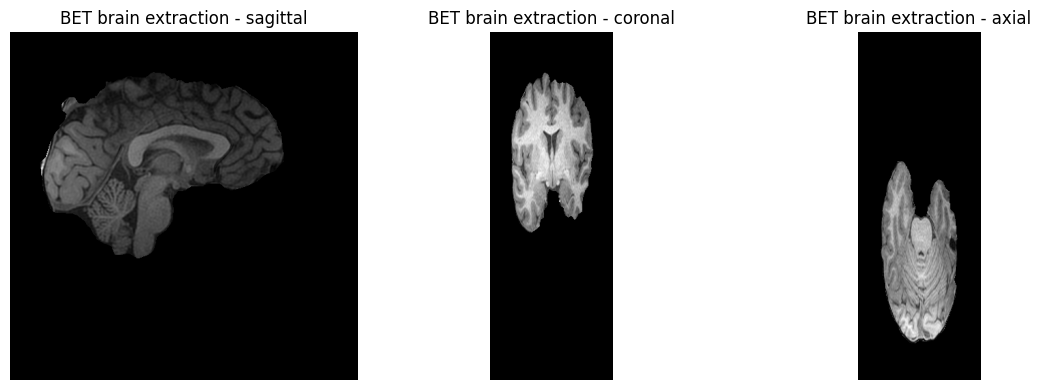

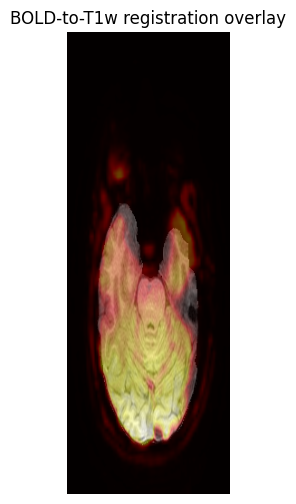

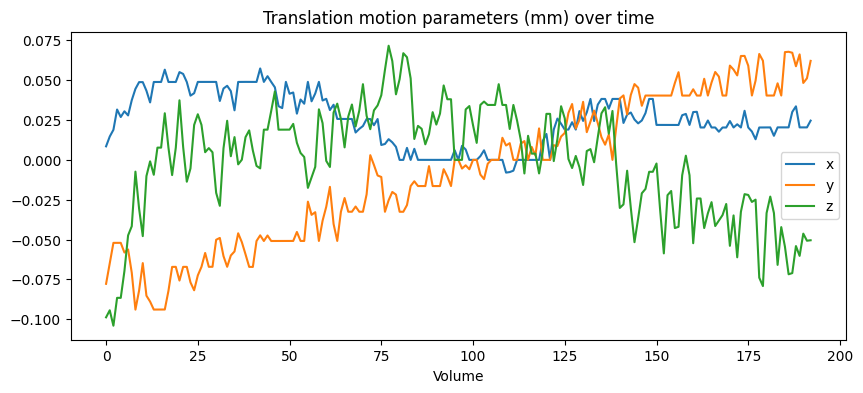

Max absolute translation: 0.10 mm


In [11]:
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

def plot_middle_slices(img_path, title):
    img = nib.load(img_path)
    data = img.get_fdata()
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    mid = [size // 2 for size in data.shape]
    axes[0].imshow(np.rot90(data[mid[0], :, :]), cmap='gray')
    axes[0].set_title(f'{title} - sagittal')
    axes[1].imshow(np.rot90(data[:, mid[1], :]), cmap='gray')
    axes[1].set_title(f'{title} - coronal')
    axes[2].imshow(np.rot90(data[:, :, mid[2]]), cmap='gray')
    axes[2].set_title(f'{title} - axial')
    for axis in axes:
        axis.axis('off')
    plt.tight_layout()
    plt.show()

# 1. Verify that BET retained brain tissue and removed non-brain tissue.
plot_middle_slices(f'{work_dir}/T1w_brain.nii.gz', 'BET brain extraction')

# 2. Verify BOLD-to-T1w alignment with a mid-axial overlay.
t1_img = nib.load(f'{work_dir}/T1w_brain.nii.gz').get_fdata()
bold_reg_img = nib.load(f'{work_dir}/rest_mc_mean_to_T1w.nii.gz').get_fdata()
mid = t1_img.shape[2] // 2
fig, axis = plt.subplots(figsize=(6, 6))
axis.imshow(np.rot90(t1_img[:, :, mid]), cmap='gray')
axis.imshow(np.rot90(bold_reg_img[:, :, mid]), cmap='hot', alpha=0.4)
axis.set_title('BOLD-to-T1w registration overlay')
axis.axis('off')
plt.show()

# 3. Inspect the translational MCFLIRT motion parameters.
motion = np.loadtxt(f'{work_dir}/rest_mc.par')
fig, axis = plt.subplots(figsize=(10, 4))
axis.plot(motion[:, 3:])
axis.set_title('Translation motion parameters (mm) over time')
axis.set_xlabel('Volume')
axis.legend(['x', 'y', 'z'])
plt.show()
print(f'Max absolute translation: {np.abs(motion[:, 3:]).max():.2f} mm')


## Step 11 - Preprocess the Cohort with Per-Session Checkpoints

Process every session containing a resting-state BOLD file using the validated local-disk workflow. A `DONE` marker is created only after the required outputs and QC record have been copied to Drive, so rerunning the cell skips completed sessions after a Colab interruption. The run log is updated after every session, including failures and missing inputs.

In [12]:
import json
import shutil
import subprocess
import time
from pathlib import Path

import numpy as np

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
output_root.mkdir(parents=True, exist_ok=True)
log_path = output_root / 'preprocessing_log.json'

def run_fsl_step(command, label, log):
    start_time = time.time()
    full_command = f'source /usr/local/fsl/etc/fslconf/fsl.sh && {command}'
    result = subprocess.run(['bash', '-c', full_command], capture_output=True, text=True)
    elapsed = time.time() - start_time
    ok = result.returncode == 0
    record = {'step': label, 'ok': ok, 'seconds': round(elapsed, 1)}
    if not ok:
        record['stderr'] = result.stderr[-1000:]
    log.append(record)
    return ok

def preprocess_session(subject, session):
    out_dir = output_root / subject / session
    done_marker = out_dir / 'DONE'
    if done_marker.exists():
        return 'skipped', None

    t1w_src = drive_root / subject / session / 'anat' / f'{subject}_{session}_T1w.nii.gz'
    rest_src = drive_root / subject / session / 'func' / f'{subject}_{session}_task-rest_bold.nii.gz'
    if not t1w_src.exists() or not rest_src.exists():
        return 'missing_input', None

    work_dir = Path(f'/content/work/{subject}_{session}')
    work_dir.mkdir(parents=True, exist_ok=True)
    log = []
    try:
        shutil.copy(t1w_src, work_dir / 'T1w.nii.gz')
        shutil.copy(rest_src, work_dir / 'rest.nii.gz')

        ok1 = run_fsl_step(f'mcflirt -in {work_dir}/rest.nii.gz -out {work_dir}/rest_mc -plots -mats', 'mcflirt', log)
        ok2 = run_fsl_step(f'bet {work_dir}/T1w.nii.gz {work_dir}/T1w_brain -R -f 0.5', 'bet', log)
        ok3 = run_fsl_step(f'fslmaths {work_dir}/rest_mc -Tmean {work_dir}/rest_mc_mean', 'mean_bold', log)
        ok4 = run_fsl_step(
            f'flirt -in {work_dir}/rest_mc_mean -ref {work_dir}/T1w_brain ' 
            f'-out {work_dir}/rest_mc_mean_to_T1w -omat {work_dir}/rest_to_T1w.mat -dof 6',
            'flirt', log
        )
        if not (ok1 and ok2 and ok3 and ok4):
            return 'failed', {'log': log}

        motion = np.loadtxt(work_dir / 'rest_mc.par')
        max_translation = float(np.abs(motion[:, 3:]).max())

        out_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy(work_dir / 'rest_mc.nii.gz', out_dir / 'rest_mc.nii.gz')
        shutil.copy(work_dir / 'rest_mc.par', out_dir / 'rest_mc.par')
        shutil.copy(work_dir / 'rest_to_T1w.mat', out_dir / 'rest_to_T1w.mat')
        shutil.copy(work_dir / 'T1w_brain.nii.gz', out_dir / 'T1w_brain.nii.gz')
        with open(out_dir / 'qc.json', 'w') as handle:
            json.dump({'max_translation_mm': max_translation, 'log': log}, handle, indent=2)

        done_marker.touch()
        return 'success', {'max_translation_mm': max_translation}
    finally:
        shutil.rmtree(work_dir, ignore_errors=True)

sessions = sorted({
    (path.parts[-4], path.parts[-3])
    for path in drive_root.glob('sub-*/ses-*/func/*task-rest_bold.nii.gz')
})
print(f'Found {len(sessions)} resting-state sessions to process.')

results = {'success': 0, 'skipped': 0, 'failed': 0, 'missing_input': 0}
run_records = []
for index, (subject, session) in enumerate(sessions, start=1):
    status, info = preprocess_session(subject, session)
    results[status] += 1
    record = {'subject': subject, 'session': session, 'status': status, 'info': info}
    run_records.append(record)
    with open(log_path, 'w') as handle:
        json.dump(run_records, handle, indent=2)
    print(f'[{index}/{len(sessions)}] {subject} {session}: {status}' + (f' ({info})' if info else ''))

print('\nSummary:', results)
print(f'Run log saved to: {log_path}')


Found 165 resting-state sessions to process.
[1/165] sub-9001 ses-1: skipped
[2/165] sub-9001 ses-2: skipped
[3/165] sub-9002 ses-1: skipped
[4/165] sub-9002 ses-2: skipped
[5/165] sub-9003 ses-1: skipped
[6/165] sub-9003 ses-2: skipped
[7/165] sub-9004 ses-1: skipped
[8/165] sub-9004 ses-2: skipped
[9/165] sub-9005 ses-1: skipped
[10/165] sub-9005 ses-2: skipped
[11/165] sub-9007 ses-1: skipped
[12/165] sub-9007 ses-2: skipped
[13/165] sub-9008 ses-1: skipped
[14/165] sub-9008 ses-2: skipped
[15/165] sub-9009 ses-1: skipped
[16/165] sub-9009 ses-2: skipped
[17/165] sub-9011 ses-1: skipped
[18/165] sub-9011 ses-2: skipped
[19/165] sub-9012 ses-1: skipped
[20/165] sub-9012 ses-2: skipped
[21/165] sub-9013 ses-1: skipped
[22/165] sub-9013 ses-2: skipped
[23/165] sub-9014 ses-1: skipped
[24/165] sub-9014 ses-2: skipped
[25/165] sub-9016 ses-1: skipped
[26/165] sub-9017 ses-1: skipped
[27/165] sub-9017 ses-2: skipped
[28/165] sub-9018 ses-1: skipped
[29/165] sub-9018 ses-2: skipped
[30/165

## Step 12 - Normalize the Motion-Corrected BOLD Runs to MNI Space

The Schaefer atlas is defined in MNI space. Step 11 saved each motion-corrected run in native functional space and its functional-to-T1w matrix, so this resumable step estimates a T1w-to-MNI affine transform, concatenates the transforms, and resamples each 4D BOLD run to the 2 mm MNI template. A separate `MNI_DONE` marker makes this safe to resume after a Colab interruption.

In [13]:
import os
import subprocess
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
fsl_dir = Path('/usr/local/fsl')
mni_template = fsl_dir / 'data/standard/MNI152_T1_2mm_brain.nii.gz'

if not mni_template.exists():
    raise FileNotFoundError(f'FSL MNI template not found: {mni_template}')

fsl_env = os.environ.copy()
fsl_env['FSLDIR'] = str(fsl_dir)
fsl_env['PATH'] = f"{fsl_dir / 'bin'}:{fsl_env['PATH']}"
fsl_env['FSLOUTPUTTYPE'] = 'NIFTI_GZ'

def run_fsl_command(command):
    result = subprocess.run(command, env=fsl_env, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(
            f'Command failed ({result.returncode}): {" ".join(map(str, command))}\n'
            f'{result.stderr[-2000:]}'
        )

# Step 14 MNI QC passed; process every available preprocessed session.
test_mode = False
test_subject, test_session = 'sub-9001', 'ses-1'
if test_mode:
    session_dirs = [output_root / test_subject / test_session]
else:
    session_dirs = sorted(path for path in output_root.glob('sub-*/ses-*') if path.is_dir())
normalized = 0
skipped = 0

for session_dir in session_dirs:
    rest_mc = session_dir / 'rest_mc.nii.gz'
    t1w_brain = session_dir / 'T1w_brain.nii.gz'
    rest_to_t1w = session_dir / 'rest_to_T1w.mat'
    t1w_to_mni = session_dir / 'T1w_to_MNI.mat'
    rest_to_mni = session_dir / 'rest_to_MNI.mat'
    rest_mc_mni = session_dir / 'rest_mc_MNI.nii.gz'
    done_marker = session_dir / 'MNI_DONE'

    if done_marker.exists() and rest_mc_mni.exists() and rest_to_mni.exists():
        skipped += 1
        continue

    required = [rest_mc, t1w_brain, rest_to_t1w]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        print(f'Skipping {session_dir.relative_to(output_root)}; missing: {missing}')
        continue

    run_fsl_command([
        'flirt', '-in', str(t1w_brain), '-ref', str(mni_template),
        '-omat', str(t1w_to_mni), '-dof', '12'
    ])
    run_fsl_command([
        'convert_xfm', '-omat', str(rest_to_mni), '-concat',
        str(t1w_to_mni), str(rest_to_t1w)
    ])
    run_fsl_command([
        'applyxfm4D', str(rest_mc), str(mni_template), str(rest_mc_mni),
        str(rest_to_mni), '-singlematrix'
    ])

    if not rest_mc_mni.exists():
        raise RuntimeError(f'MNI-space BOLD was not created: {rest_mc_mni}')

    done_marker.touch()
    normalized += 1
    print(f'Normalized {session_dir.relative_to(output_root)}')

print(f'Normalization summary: {normalized} completed, {skipped} skipped.')


Normalization summary: 0 completed, 165 skipped.


## Step 13 - Install Nilearn and Validate Schaefer-400 Time-Series Extraction

Install the session-local Nilearn dependencies, read the repetition time from the raw BIDS sidecar, then extract Schaefer-400 ROI time series from one MNI-space BOLD run. Do not use native-space `rest_mc.nii.gz` for this step.

In [14]:
import json
import subprocess
import sys
from pathlib import Path

subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', 'nilearn', 'nibabel'], check=True)

import nibabel
import nilearn
import numpy as np
from nilearn import datasets
from nilearn.maskers import NiftiLabelsMasker

print(f'Nilearn version: {nilearn.__version__}')
print(f'Nibabel version: {nibabel.__version__}')

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
sub, ses = 'sub-9001', 'ses-1'

bold_path = output_root / sub / ses / 'rest_mc_MNI.nii.gz'
json_path = drive_root / sub / ses / 'func' / f'{sub}_{ses}_task-rest_bold.json'

if not bold_path.exists():
    raise FileNotFoundError(f'MNI-space BOLD file not found: {bold_path}')

with open(json_path) as file:
    repetition_time = json.load(file).get('RepetitionTime')

if repetition_time is None:
    raise ValueError(f'RepetitionTime is missing from {json_path}')

schaefer = datasets.fetch_atlas_schaefer_2018(
    n_rois=400,
    yeo_networks=7,
    resolution_mm=2,
)
labels = [
    label.decode() if isinstance(label, bytes) else label
    for label in schaefer.labels
]

masker = NiftiLabelsMasker(
    labels_img=schaefer.maps,
    standardize='zscore_sample',
    detrend=True,
    low_pass=0.1,
    high_pass=0.01,
    t_r=repetition_time,
)
time_series = masker.fit_transform(str(bold_path))

print(f'RepetitionTime: {repetition_time} s')
print(f'Atlas loaded: {len(labels)} ROIs')
print('Sample labels:', labels[:5])
print(f'Using BOLD: {bold_path}')
print(f'Extracted time series shape: {time_series.shape} (timepoints x ROIs)')
print(f'Any NaNs: {np.isnan(time_series).any()}')


Nilearn version: 0.14.1
Nibabel version: 5.4.2


[fetch_atlas_schaefer_2018] Added README.md to /root/nilearn_data

[fetch_atlas_schaefer_2018] Dataset created in /root/nilearn_data/schaefer_2018

[fetch_atlas_schaefer_2018] Downloading data from https://raw.githubusercontent.com/ThomasYeoLab/CBIG/v0.14.3-Update_Yeo2011_Schaefer2018_labelname/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal/Parcellations/MNI/Schaefer2018_400Parcels_7Networks_order.txt ...

[fetch_atlas_schaefer_2018]  ...done. (0 seconds, 0 min)

[fetch_atlas_schaefer_2018] Downloading data from https://raw.githubusercontent.com/ThomasYeoLab/CBIG/v0.14.3-Update_Yeo2011_Schaefer2018_labelname/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal/Parcellations/MNI/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_2mm.nii.gz ...

[fetch_atlas_schaefer_2018]  ...done. (0 seconds, 0 min)

RepetitionTime: 2.5 s
Atlas loaded: 401 ROIs
Sample labels: ['Background', '7Networks_LH_Vis_1', '7Networks_LH_Vis_2', '7Networks_LH_Vis_3', '7Networks_LH_Vis_4']
Using BOLD: /content/drive/MyDrive/sem 4 project (1)/preprocessed/sub-9001/ses-1/rest_mc_MNI.nii.gz
Extracted time series shape: (193, 400) (timepoints x ROIs)
Any NaNs: False


## Step 14 - Visually Quality-Control the Affine MNI Normalization

Resample the extracted T1w brain into the FSL MNI152 template grid using the saved 12-DOF transform, then overlay it on the template. This checks the actual affine MNI registration used for atlas extraction. Inspect major cortical boundaries, ventricles, and the midline for a sensible match before switching Step 12 from test mode to cohort mode.

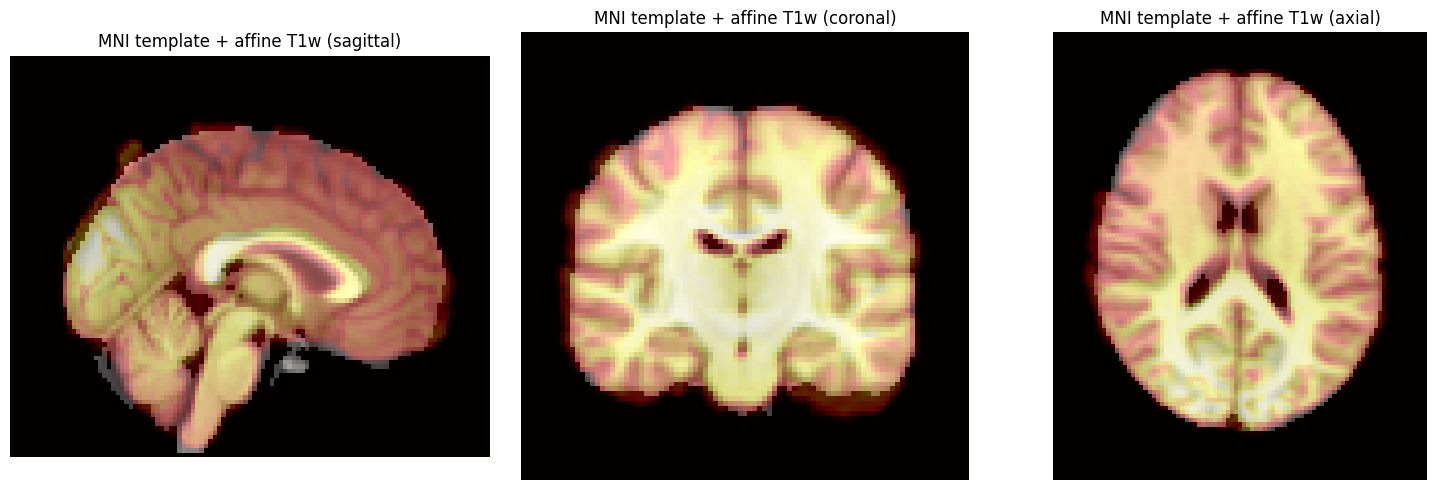

QC image: /content/drive/MyDrive/sem 4 project (1)/preprocessed/sub-9001/ses-1/T1w_brain_MNI_qc.nii.gz


In [15]:
import os
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
session_dir = output_root / 'sub-9001' / 'ses-1'
fsl_dir = Path('/usr/local/fsl')
mni_template = fsl_dir / 'data/standard/MNI152_T1_2mm_brain.nii.gz'
t1w_brain = session_dir / 'T1w_brain.nii.gz'
t1w_to_mni = session_dir / 'T1w_to_MNI.mat'
t1w_mni_qc = session_dir / 'T1w_brain_MNI_qc.nii.gz'

required = [mni_template, t1w_brain, t1w_to_mni]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(f'Missing MNI-QC input(s): {missing}')

if not t1w_mni_qc.exists():
    fsl_env = os.environ.copy()
    fsl_env['FSLDIR'] = str(fsl_dir)
    fsl_env['PATH'] = f"{fsl_dir / 'bin'}:{fsl_env['PATH']}"
    result = subprocess.run([
        'flirt', '-in', str(t1w_brain), '-ref', str(mni_template),
        '-applyxfm', '-init', str(t1w_to_mni), '-out', str(t1w_mni_qc),
    ], env=fsl_env, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(result.stderr[-2000:])

mni_data = nib.load(mni_template).get_fdata()
t1_mni_data = nib.load(t1w_mni_qc).get_fdata()
if mni_data.shape != t1_mni_data.shape:
    raise ValueError(f'Grid mismatch: template {mni_data.shape}, T1w {t1_mni_data.shape}')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
slice_indices = [mni_data.shape[0] // 2, mni_data.shape[1] // 2, mni_data.shape[2] // 2]
views = [
    (np.rot90(mni_data[slice_indices[0], :, :]), np.rot90(t1_mni_data[slice_indices[0], :, :]), 'sagittal'),
    (np.rot90(mni_data[:, slice_indices[1], :]), np.rot90(t1_mni_data[:, slice_indices[1], :]), 'coronal'),
    (np.rot90(mni_data[:, :, slice_indices[2]]), np.rot90(t1_mni_data[:, :, slice_indices[2]]), 'axial'),
]
for axis, (template_slice, t1_slice, view_name) in zip(axes, views):
    axis.imshow(template_slice, cmap='gray')
    axis.imshow(t1_slice, cmap='hot', alpha=0.35)
    axis.set_title(f'MNI template + affine T1w ({view_name})')
    axis.axis('off')
plt.tight_layout()
plt.show()
print(f'QC image: {t1w_mni_qc}')


## Step 15 - Extract and Checkpoint Schaefer-400 Time Series for the Cohort

For every session with a completed MNI-normalized BOLD run, read its own BIDS repetition time, apply the validated Schaefer-400 masker, and immediately save the ROI time-series array and metadata in that session's preprocessing directory. A `SCHAEFER400_DONE` marker makes the process safe to resume after a Colab interruption.

In [16]:
import json
from pathlib import Path

import numpy as np
from nilearn import datasets
from nilearn.maskers import NiftiLabelsMasker

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
batch_log_path = output_root / 'schaefer400_extraction_log.json'

schaefer = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2)
labels = [label.decode() if isinstance(label, bytes) else label for label in schaefer.labels]

def extract_session_timeseries(session_dir):
    subject = session_dir.parent.name
    session = session_dir.name
    done_marker = session_dir / 'SCHAEFER400_DONE'
    array_path = session_dir / 'schaefer400_timeseries.npy'
    metadata_path = session_dir / 'schaefer400_timeseries.json'
    bold_path = session_dir / 'rest_mc_MNI.nii.gz'
    json_path = drive_root / subject / session / 'func' / f'{subject}_{session}_task-rest_bold.json'

    if done_marker.exists() and array_path.exists() and metadata_path.exists():
        return 'skipped', None
    if not bold_path.exists() or not json_path.exists():
        return 'missing_input', None

    with open(json_path) as handle:
        repetition_time = json.load(handle).get('RepetitionTime')
    if repetition_time is None:
        return 'missing_tr', None

    masker = NiftiLabelsMasker(
        labels_img=schaefer.maps,
        standardize='zscore_sample',
        detrend=True,
        low_pass=0.1,
        high_pass=0.01,
        t_r=float(repetition_time),
    )
    time_series = masker.fit_transform(str(bold_path))
    if time_series.ndim != 2 or time_series.shape[1] != 400 or np.isnan(time_series).any():
        return 'invalid_output', {'shape': list(time_series.shape), 'has_nan': bool(np.isnan(time_series).any())}

    np.save(array_path, time_series.astype(np.float32))
    metadata = {
        'subject': subject,
        'session': session,
        'atlas': 'Schaefer2018_400Parcels_7Networks_2mm',
        'repetition_time_s': float(repetition_time),
        'shape_timepoints_by_rois': list(time_series.shape),
        'labels': labels,
        'source_bold': str(bold_path),
    }
    with open(metadata_path, 'w') as handle:
        json.dump(metadata, handle, indent=2)
    done_marker.touch()
    return 'success', {'shape': list(time_series.shape), 'tr_s': float(repetition_time)}

session_dirs = sorted(path for path in output_root.glob('sub-*/ses-*') if path.is_dir())
print(f'Found {len(session_dirs)} preprocessed session directories.')

results = {'success': 0, 'skipped': 0, 'missing_input': 0, 'missing_tr': 0, 'invalid_output': 0, 'failed': 0}
run_records = []
for index, session_dir in enumerate(session_dirs, start=1):
    try:
        status, info = extract_session_timeseries(session_dir)
    except Exception as error:
        status, info = 'failed', {'error': str(error)}
    results[status] += 1
    record = {'subject': session_dir.parent.name, 'session': session_dir.name, 'status': status, 'info': info}
    run_records.append(record)
    with open(batch_log_path, 'w') as handle:
        json.dump(run_records, handle, indent=2)
    print(f'[{index}/{len(session_dirs)}] {record["subject"]} {record["session"]}: {status}' + (f' ({info})' if info else ''))

print('\nSummary:', results)
print(f'Extraction log saved to: {batch_log_path}')


[fetch_atlas_schaefer_2018] Dataset directory found: /root/nilearn_data/schaefer_2018

Found 165 preprocessed session directories.
[1/165] sub-9001 ses-1: skipped
[2/165] sub-9001 ses-2: skipped
[3/165] sub-9002 ses-1: skipped
[4/165] sub-9002 ses-2: skipped
[5/165] sub-9003 ses-1: skipped
[6/165] sub-9003 ses-2: skipped
[7/165] sub-9004 ses-1: skipped
[8/165] sub-9004 ses-2: skipped
[9/165] sub-9005 ses-1: skipped
[10/165] sub-9005 ses-2: skipped
[11/165] sub-9007 ses-1: skipped
[12/165] sub-9007 ses-2: skipped
[13/165] sub-9008 ses-1: skipped
[14/165] sub-9008 ses-2: skipped
[15/165] sub-9009 ses-1: skipped
[16/165] sub-9009 ses-2: skipped
[17/165] sub-9011 ses-1: skipped
[18/165] sub-9011 ses-2: skipped
[19/165] sub-9012 ses-1: skipped
[20/165] sub-9012 ses-2: skipped
[21/165] sub-9013 ses-1: skipped
[22/165] sub-9013 ses-2: skipped
[23/165] sub-9014 ses-1: skipped
[24/165] sub-9014 ses-2: skipped
[25/165] sub-9016 ses-1: skipped
[26/165] sub-9017 ses-1: skipped
[27/165] sub-9017 ses-2: skipped
[28/165] sub-9018 ses-1: skipped
[29/165] sub-9018 ses-2: skipped
[30/165]

## Step 16a - Verify Experimental Design and Session Mapping

Inspect `participants.tsv`, `sessions.tsv`, and directory layouts to confirm whether PVT data is behavioral (out-of-scanner) vs functional (BOLD), and determine the randomized crossover mapping for rested versus sleep-deprived conditions across sessions.

In [17]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

print(pd.read_csv(drive_root / 'participants.tsv', sep='\t').head(10).to_string())
print("\nsessions files:", list(drive_root.glob('sub-9001/*sessions.tsv')))
print("PVT in func/:", list(drive_root.glob('sub-9001/ses-*/func/*PVT*')))
print("\nAll files, sub-9001 ses-1:")
for p in sorted(drive_root.glob('sub-9001/ses-1/**/*')):
    if p.is_file():
        print(" ", p.relative_to(drive_root))


  participant_id     Sex AgeGroup         BMI1         BMI2                                   EducationLevel  HADS_Anxiety  HADS_Depression  ISI KSQ_SleepQualityIndex KSQ_WakeupSymptomIndex KSQ_SnoringSymptomIndex KSQ_SleepSymptomIndex KSQ_WeekdayBedTime KSQ_WeekendBedTime KSQ_WeekdayRiseTime KSQ_WeekendRiseTime          KSQ_NapFrequency KSQ_NapDuration KSQ_ConcernDisturbedSleep              KSQ_Panic              KSQ_Worry KSQ_CompensatoryMorningSleep    KSQ_ConcernFatigue                  KSQ_EnoughSleep       KSQ_HealthProblem KSQ_TotalSleepRequirement    KSQ_OverallSleepQuality  KSQ_MorningOrEveningPerson       IRI_EC       IRI_PT       IRI_PD        IRI_F  TAS20_Total  TAS20_DIF  TAS20_DDF  TAS20_EOT  STAI_T  BFI_Extraversion  BFI_Agreeableness  BFI_Conscientiousness  BFI_Neuroticism  BFI_Openness  PAn/aS_Positive  PAn/aS_Negative  PSS14  SelfRatedHealth  SRH5  ESS  SicknessQ          ECS  BIS11_Total BIS11_Attentional  BIS11_Motor BIS11_Nonplanning MenstrualPhaseSession1 Menstrua

## Step 16b - Re-extract Schaefer-400 Time Series with Confound Regression and Motion QC

Extract Schaefer-400 ROI time series with full confound regression:
- 6 MCFLIRT head motion parameters (`.par`) + 6 first temporal derivatives
- 5 CompCor components (`high_variance_confounds`)
- Bandpass filtering (0.01 - 0.10 Hz) & sample z-scoring
- Per-session Framewise Displacement (FD) calculation using Power et al. formula (50 mm head radius)
- Saves clean arrays `schaefer400_clean_timeseries.npy`, `fd.npy`, and exports `motion_qc_table.csv`

In [18]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from nilearn import datasets
from nilearn.maskers import NiftiLabelsMasker
from nilearn.image import high_variance_confounds

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
schaefer = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2)

def framewise_displacement(par):
    # MCFLIRT .par: cols 0-2 rotations (rad), cols 3-5 translations (mm); Power et al. FD with 50 mm head radius
    d = np.abs(np.diff(par, axis=0))
    return np.insert(d[:, 3:].sum(axis=1) + 50 * d[:, :3].sum(axis=1), 0, 0.0)

def clean_session(session_dir):
    marker = session_dir / 'SCHAEFER400_CLEAN_DONE'
    bold = session_dir / 'rest_mc_MNI.nii.gz'
    par_path = session_dir / 'rest_mc.par'
    sub, ses = session_dir.parent.name, session_dir.name
    json_path = drive_root / sub / ses / 'func' / f'{sub}_{ses}_task-rest_bold.json'
    if marker.exists():
        return 'skipped', None
    if not (bold.exists() and par_path.exists() and json_path.exists()):
        return 'missing_input', None

    tr = float(json.load(open(json_path))['RepetitionTime'])
    par = np.loadtxt(par_path)
    deriv = np.vstack([np.zeros((1, 6)), np.diff(par, axis=0)])
    compcor = high_variance_confounds(str(bold), n_confounds=5, percentile=2.0)
    confounds = np.hstack([par, deriv, compcor])   # 6 motion + 6 derivatives + 5 tCompCor

    masker = NiftiLabelsMasker(labels_img=schaefer.maps, standardize='zscore_sample',
                               detrend=True, low_pass=0.1, high_pass=0.01, t_r=tr)
    ts = masker.fit_transform(str(bold), confounds=confounds)
    if ts.shape[1] != 400 or np.isnan(ts).any():
        return 'invalid_output', {'shape': list(ts.shape)}

    fd = framewise_displacement(par)
    np.save(session_dir / 'schaefer400_clean_timeseries.npy', ts.astype(np.float32))
    np.save(session_dir / 'fd.npy', fd.astype(np.float32))
    marker.touch()
    return 'success', {'shape': list(ts.shape), 'mean_fd': round(float(fd.mean()), 3)}

session_dirs = sorted(p for p in output_root.glob('sub-*/ses-*') if p.is_dir())
results, rows = {}, []
for i, sd in enumerate(session_dirs, 1):
    try:
        status, info = clean_session(sd)
    except Exception as e:
        status, info = 'failed', {'error': str(e)[:200]}
    results[status] = results.get(status, 0) + 1
    print(f'[{i}/{len(session_dirs)}] {sd.parent.name} {sd.name}: {status} {info or ""}')

# motion QC table from saved FD arrays
for sd in session_dirs:
    fd_path = sd / 'fd.npy'
    if fd_path.exists():
        fd = np.load(fd_path)
        rows.append({'subject': sd.parent.name, 'session': sd.name, 'n_vols': len(fd),
                     'mean_fd': fd.mean(), 'max_fd': fd.max(), 'pct_fd_gt_0.5': (fd > 0.5).mean() * 100})
pd.DataFrame(rows).to_csv(output_root / 'motion_qc_table.csv', index=False)
print('\nSummary:', results)


[fetch_atlas_schaefer_2018] Dataset directory found: /root/nilearn_data/schaefer_2018

[1/165] sub-9001 ses-1: skipped 
[2/165] sub-9001 ses-2: skipped 
[3/165] sub-9002 ses-1: skipped 
[4/165] sub-9002 ses-2: skipped 
[5/165] sub-9003 ses-1: skipped 
[6/165] sub-9003 ses-2: skipped 
[7/165] sub-9004 ses-1: skipped 
[8/165] sub-9004 ses-2: skipped 
[9/165] sub-9005 ses-1: skipped 
[10/165] sub-9005 ses-2: skipped 
[11/165] sub-9007 ses-1: skipped 
[12/165] sub-9007 ses-2: skipped 
[13/165] sub-9008 ses-1: skipped 
[14/165] sub-9008 ses-2: skipped 
[15/165] sub-9009 ses-1: skipped 
[16/165] sub-9009 ses-2: skipped 
[17/165] sub-9011 ses-1: skipped 
[18/165] sub-9011 ses-2: skipped 
[19/165] sub-9012 ses-1: skipped 
[20/165] sub-9012 ses-2: skipped 
[21/165] sub-9013 ses-1: skipped 
[22/165] sub-9013 ses-2: skipped 
[23/165] sub-9014 ses-1: skipped 
[24/165] sub-9014 ses-2: skipped 
[25/165] sub-9016 ses-1: skipped 
[26/165] sub-9017 ses-1: skipped 
[27/165] sub-9017 ses-2: skipped 
[28/165] sub-9018 ses-1: skipped 
[29/165] sub-9018 ses-2: skipped 
[30/165] sub-9019 ses-1

## Step 16c - Visualize Motion Quality Control (Framewise Displacement Distributions)

Generate cohort-level motion quality control plots:
- Distribution of session mean Framewise Displacement (FD)
- Proportion of high-motion volumes (>0.5 mm)
- Exemplar temporal FD trace across TRs for sub-9001 (rested vs sleep-deprived)

Motion QC plot saved to: /content/drive/MyDrive/sem 4 project (1)/preprocessed/qc_motion_distribution.png


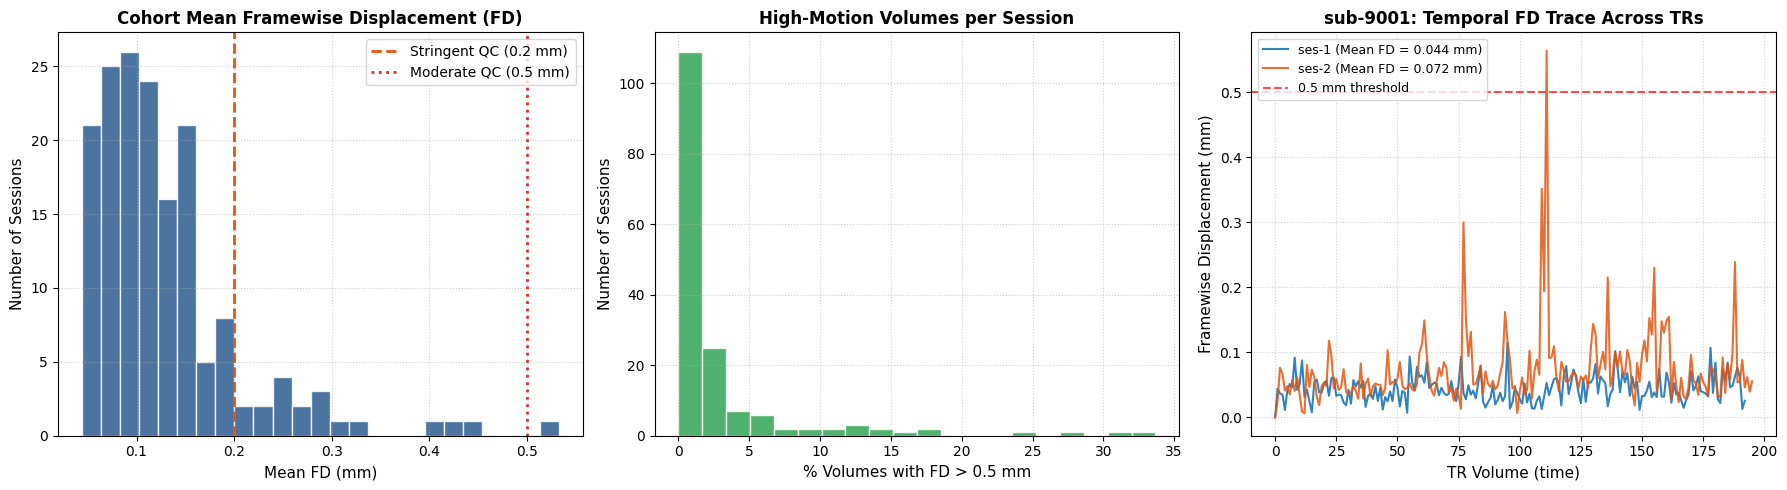

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
motion_file = output_root / 'motion_qc_table.csv'

if motion_file.exists():
    motion_df = pd.read_csv(motion_file)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Mean FD Distribution across Cohort
    axes[0].hist(motion_df['mean_fd'], bins=25, color='#2b5c8f', edgecolor='white', alpha=0.85)
    axes[0].axvline(0.2, color='#e6550d', linestyle='--', linewidth=2, label='Stringent QC (0.2 mm)')
    axes[0].axvline(0.5, color='#de2d26', linestyle=':', linewidth=2, label='Moderate QC (0.5 mm)')
    axes[0].set_title('Cohort Mean Framewise Displacement (FD)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Mean FD (mm)', fontsize=11)
    axes[0].set_ylabel('Number of Sessions', fontsize=11)
    axes[0].legend(frameon=True)
    axes[0].grid(True, linestyle=':', alpha=0.6)

    # 2. Percentage of volumes with FD > 0.5 mm
    axes[1].hist(motion_df['pct_fd_gt_0.5'], bins=20, color='#31a354', edgecolor='white', alpha=0.85)
    axes[1].set_title('High-Motion Volumes per Session', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('% Volumes with FD > 0.5 mm', fontsize=11)
    axes[1].set_ylabel('Number of Sessions', fontsize=11)
    axes[1].grid(True, linestyle=':', alpha=0.6)

    # 3. Example temporal FD trace from reference subject sub-9001
    fd_ses1_path = output_root / 'sub-9001' / 'ses-1' / 'fd.npy'
    fd_ses2_path = output_root / 'sub-9001' / 'ses-2' / 'fd.npy'
    if fd_ses1_path.exists() and fd_ses2_path.exists():
        fd1 = np.load(fd_ses1_path)
        fd2 = np.load(fd_ses2_path)
        axes[2].plot(fd1, color='#3182bd', label=f'ses-1 (Mean FD = {fd1.mean():.3f} mm)', linewidth=1.5)
        axes[2].plot(fd2, color='#e6550d', label=f'ses-2 (Mean FD = {fd2.mean():.3f} mm)', linewidth=1.5, alpha=0.85)
        axes[2].axhline(0.5, color='red', linestyle='--', alpha=0.7, label='0.5 mm threshold')
        axes[2].set_title('sub-9001: Temporal FD Trace Across TRs', fontsize=12, fontweight='bold')
        axes[2].set_xlabel('TR Volume (time)', fontsize=11)
        axes[2].set_ylabel('Framewise Displacement (mm)', fontsize=11)
        axes[2].legend(frameon=True, fontsize=9)
        axes[2].grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    save_path = output_root / 'qc_motion_distribution.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Motion QC plot saved to: {save_path}")
    plt.show()
else:
    print("motion_qc_table.csv not found yet.")


## Step 17 - Read the Condition Mapping (Rested vs. Sleep-Deprived)

Inspect subject-level `*_sessions.tsv` and `participants.tsv` to identify the crossover session-to-condition mapping across all participants and confirm counterbalancing.

In [20]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

sessions_df = pd.read_csv(drive_root / 'sub-9001' / 'sub-9001_sessions.tsv', sep='\t')
print("=== sub-9001_sessions.tsv ===")
print(sessions_df.to_string())

participants_df = pd.read_csv(drive_root / 'participants.tsv', sep='\t')
print("\n=== participants.tsv columns ===")
print(list(participants_df.columns))

# check whether every subject has the same session->condition mapping, or if it's randomized per-subject
import re
all_sessions = []
for f in sorted(drive_root.glob('sub-*/sub-*_sessions.tsv')):
    d = pd.read_csv(f, sep='\t')
    d['subject'] = f.parts[-2]
    all_sessions.append(d)
combined = pd.concat(all_sessions, ignore_index=True)
print(f"\n=== combined sessions.tsv across {combined['subject'].nunique()} subjects ===")
print(combined.head(20).to_string())
print("\nColumns:", list(combined.columns))


=== sub-9001_sessions.tsv ===
  session_id             acq_time  preMRI_KSS_Q0_rating  preMRI_KSS_Q1_rating  preMRI_KSS_Q2_rating  preMRI_KSS_Q3_rating  preMRI_KSS_Q4_rating  preMRI_KSS_Q5_rating  working_mem_KSS_rating  working_mem_perform_rating  working_mem_effort_rating
0      ses-1  1873-03-11T18:22:49                     3                     3                     5                     6                     7                     2                     NaN                         NaN                        NaN
1      ses-2  1873-04-08T19:08:54                     8                     8                     9                     9                     9                     9                     NaN                         NaN                        NaN

=== participants.tsv columns ===
['participant_id', 'Sex', 'AgeGroup', 'BMI1', 'BMI2', 'EducationLevel', 'HADS_Anxiety', 'HADS_Depression', 'ISI', 'KSQ_SleepQualityIndex', 'KSQ_WakeupSymptomIndex', 'KSQ_SnoringSymptomIndex', 'KSQ_Slee

## Step 18 - Build Master Condition and Label Table

Construct the session-level condition table from `participants.tsv` (`SleepDeprivedSession1`, `SleepDeprivedSession2`), cross-validate against subjective Karolinska Sleepiness Scale (KSS) ratings, and export `condition_labels.csv`.

In [21]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')

participants = pd.read_csv(drive_root / 'participants.tsv', sep='\t')
cond_cols = ['participant_id', 'SleepDeprivedSession1', 'SleepDeprivedSession2']
print(participants[cond_cols].head(15).to_string())
print("\nValue counts, SleepDeprivedSession1:", participants['SleepDeprivedSession1'].value_counts(dropna=False).to_dict())
print("Value counts, SleepDeprivedSession2:", participants['SleepDeprivedSession2'].value_counts(dropna=False).to_dict())

# reshape to long format: one row per subject/session with a clean condition label
records = []
for _, row in participants.iterrows():
    sub = row['participant_id']
    for ses_num, col in [(1, 'SleepDeprivedSession1'), (2, 'SleepDeprivedSession2')]:
        records.append({
            'subject': sub if str(sub).startswith('sub-') else f'sub-{sub}',
            'session': f'ses-{ses_num}',
            'sleep_deprived_flag': row[col],
        })
condition_df = pd.DataFrame(records)
print(f"\nCondition table: {len(condition_df)} rows")
print(condition_df.head(10).to_string())

# cross-check against KSS: does the deprived session tend to have higher pre-scan sleepiness?
sessions_all = []
for f in sorted(drive_root.glob('sub-*/sub-*_sessions.tsv')):
    d = pd.read_csv(f, sep='\t')
    d['subject'] = f.parts[-2]
    sessions_all.append(d)
sessions_combined = pd.concat(sessions_all, ignore_index=True)
sessions_combined['kss_mean'] = sessions_combined[[c for c in sessions_combined.columns if 'preMRI_KSS' in c]].mean(axis=1)

merged = condition_df.merge(sessions_combined[['subject', 'session_id', 'kss_mean']],
                             left_on=['subject', 'session'], right_on=['subject', 'session_id'])
print("\nMean KSS by sleep_deprived_flag (should be clearly higher when deprived):")
print(merged.groupby('sleep_deprived_flag')['kss_mean'].agg(['mean', 'std', 'count']))

merged.to_csv(output_root / 'condition_labels.csv', index=False)
print(f"\nSaved to {output_root / 'condition_labels.csv'}")


   participant_id SleepDeprivedSession1 SleepDeprivedSession2
0        sub-9001             SurelyNot                Surely
1        sub-9002             LikelyNot                   NaN
2        sub-9003             SurelyNot             SurelyNot
3        sub-9004                   NaN             LikelyNot
4        sub-9005             SurelyNot                Likely
5        sub-9007             SurelyNot             LikelyNot
6        sub-9008             LikelyNot                Surely
7        sub-9009             SurelyNot             Equivocal
8        sub-9011             LikelyNot                Surely
9        sub-9012             Equivocal                Surely
10       sub-9013             SurelyNot                Surely
11       sub-9014                   NaN                   NaN
12       sub-9016                Surely             Equivocal
13       sub-9017                Likely                Likely
14       sub-9018             LikelyNot                Surely

Value c

## Step 19 - Verify Objective Sleep Condition Assignment (Sl_cond) & Dataset Documentation

Inspect `Sl_cond` and `Trial` in `participants.tsv` alongside the dataset documentation (`README`, `dataset_description.json`, `participants.json`) to confirm the authoritative, objective crossover arm assignment (rested vs sleep-deprived session order).

In [22]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

participants = pd.read_csv(drive_root / 'participants.tsv', sep='\t')
print("Sl_cond value counts:", participants['Sl_cond'].value_counts(dropna=False).to_dict())
print("\nSl_cond + Trial + self-report, first 15 subjects:")
print(participants[['participant_id', 'Sl_cond', 'Trial',
                     'SleepDeprivedSession1', 'SleepDeprivedSession2']].head(15).to_string())

# check root-level documentation files for condition definitions
doc_files = [p for p in drive_root.glob('*') if p.is_file() and (p.name.startswith('README') or p.suffix in ['.json', '.txt'])]
print("\nRoot-level docs:", [p.name for p in doc_files])

for p in sorted(drive_root.glob('README*')):
    if p.is_file():
        print(f"\n=== {p.name} ===")
        print(p.read_text(errors='ignore')[:3000])

participants_json = drive_root / 'participants.json'
if participants_json.exists():
    print("\n=== participants.json ===")
    print(participants_json.read_text(errors='ignore')[:3000])


Sl_cond value counts: {2: 46, 1: 40}

Sl_cond + Trial + self-report, first 15 subjects:
   participant_id  Sl_cond Trial SleepDeprivedSession1 SleepDeprivedSession2
0        sub-9001        2     B             SurelyNot                Surely
1        sub-9002        2     B             LikelyNot                   NaN
2        sub-9003        1     B             SurelyNot             SurelyNot
3        sub-9004        1     B                   NaN             LikelyNot
4        sub-9005        2     B             SurelyNot                Likely
5        sub-9007        2     B             SurelyNot             LikelyNot
6        sub-9008        2     A             LikelyNot                Surely
7        sub-9009        1     A             SurelyNot             Equivocal
8        sub-9011        1     A             LikelyNot                Surely
9        sub-9012        2     A             Equivocal                Surely
10       sub-9013        2     B             SurelyNot           

## Step 20 - Extract Exact Sl_cond and Trial Metadata Definitions

Query `participants.json` directly for `Sl_cond`, `Trial`, `SleepDeprivedSession1`, and `SleepDeprivedSession2` to obtain the authoritative dataset definitions.

In [23]:
import json
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')

with open(drive_root / 'participants.json') as f:
    pdef = json.load(f)

for key in ['Sl_cond', 'Trial', 'SleepDeprivedSession1', 'SleepDeprivedSession2']:
    print(f"=== {key} ===")
    print(json.dumps(pdef.get(key, 'NOT FOUND'), indent=2))
    print()


=== Sl_cond ===
{
  "Description": "Sleep randomisation condition. 1 = sleep deprivation before first session, 2 = sleep deprivation before second session"
}

=== Trial ===
{
  "Description": "Trial counterbalancing condition governing event order in trial lists during fMRI experiments"
}

=== SleepDeprivedSession1 ===
{
  "Description": "experimenter's guess about participant's condition, for validation of blinding"
}

=== SleepDeprivedSession2 ===
{
  "Description": "experimenter's guess about participant's condition, for validation of blinding"
}



## Step 21 - Build the Definitive Ground-Truth Condition Table (`condition_labels.csv`)

Map `Sl_cond` (1: sleep deprivation before session 1, 2: sleep deprivation before session 2) to objective boolean `sleep_deprived` labels per participant/session, cross-validate against subjective pre-scan KSS ratings, and export `condition_labels.csv`.

In [24]:
import pandas as pd
from pathlib import Path

drive_root = Path('/content/drive/MyDrive/sem 4 project (1)/ds000201-download')
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')

participants = pd.read_csv(drive_root / 'participants.tsv', sep='\t')

records = []
for _, row in participants.iterrows():
    sub = row['participant_id']
    sub = sub if str(sub).startswith('sub-') else f'sub-{sub}'
    sl_cond = row['Sl_cond']
    # Sl_cond 1 -> deprived before ses-1; Sl_cond 2 -> deprived before ses-2
    for ses_num in [1, 2]:
        if pd.isna(sl_cond):
            deprived = None
        else:
            deprived = (int(sl_cond) == ses_num)
        records.append({'subject': sub, 'session': f'ses-{ses_num}', 'sleep_deprived': deprived})

condition_df = pd.DataFrame(records)
print("Condition counts:", condition_df['sleep_deprived'].value_counts(dropna=False).to_dict())

# cross-check against KSS -- this should now show a cleaner separation than the blinding-guess column did
sessions_all = []
for f in sorted(drive_root.glob('sub-*/sub-*_sessions.tsv')):
    d = pd.read_csv(f, sep='\t')
    d['subject'] = f.parts[-2]
    sessions_all.append(d)
sessions_combined = pd.concat(sessions_all, ignore_index=True)
sessions_combined['kss_mean'] = sessions_combined[[c for c in sessions_combined.columns if 'preMRI_KSS' in c]].mean(axis=1)

merged = condition_df.merge(sessions_combined[['subject', 'session_id', 'kss_mean']],
                             left_on=['subject', 'session'], right_on=['subject', 'session_id'])
print("\nMean KSS by TRUE sleep_deprived condition:")
print(merged.groupby('sleep_deprived')['kss_mean'].agg(['mean', 'std', 'count']))

merged[['subject', 'session', 'sleep_deprived', 'kss_mean']].to_csv(output_root / 'condition_labels.csv', index=False)
print(f"\nSaved to {output_root / 'condition_labels.csv'}")


Condition counts: {False: 86, True: 86}

Mean KSS by TRUE sleep_deprived condition:
                    mean       std  count
sleep_deprived                           
False           4.603213  1.405693     83
True            6.327912  1.562204     83

Saved to /content/drive/MyDrive/sem 4 project (1)/preprocessed/condition_labels.csv


## Step 21b - Visualize Behavioral Condition Differences (KSS Manipulation Check)

Visualize sleepiness ratings across experimental conditions:
- Rested vs. Sleep-Deprived KSS distributions with sample jitter
- Within-subject paired trajectory lines across crossover sessions

Behavioral plot saved to: /content/drive/MyDrive/sem 4 project (1)/preprocessed/behavioral_kss_manipulation_check.png


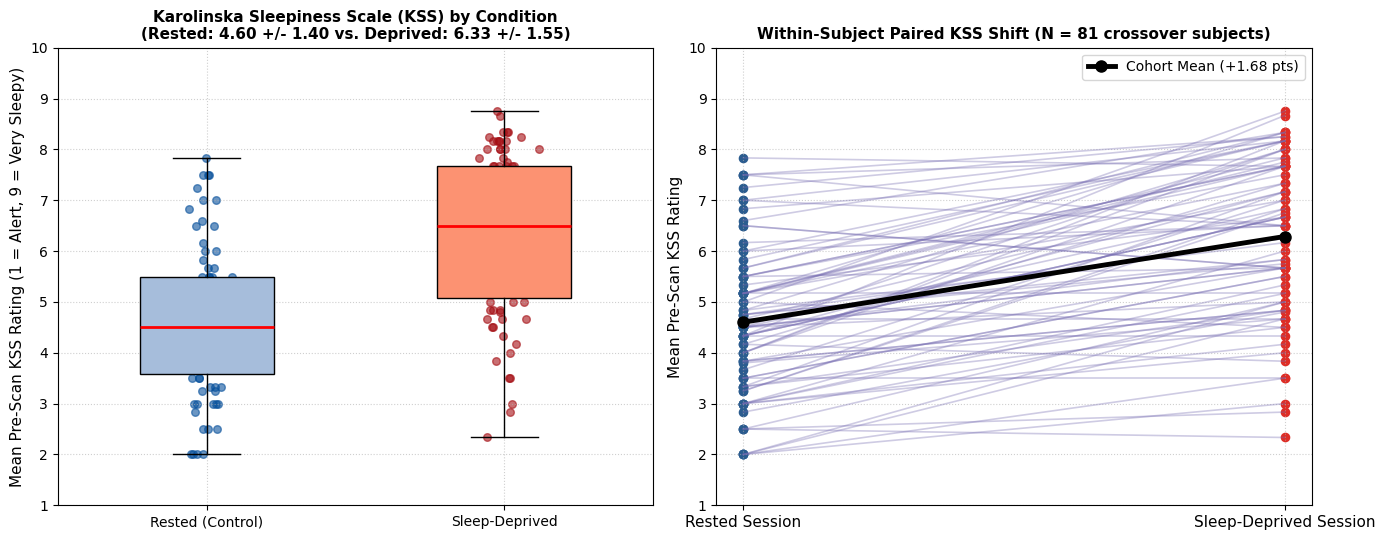

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
cond_file = output_root / 'condition_labels.csv'

if cond_file.exists():
    df = pd.read_csv(cond_file).dropna(subset=['sleep_deprived', 'kss_mean'])
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    rested_kss = df[df['sleep_deprived'] == False]['kss_mean'].values
    deprived_kss = df[df['sleep_deprived'] == True]['kss_mean'].values

    # 1. Boxplot + Swarm of KSS by Condition (supports Matplotlib >= 3.9 and older versions)
    box_kwargs = dict(patch_artist=True, widths=0.45, medianprops=dict(color='red', linewidth=2))
    try:
        box = axes[0].boxplot([rested_kss, deprived_kss], tick_labels=['Rested (Control)', 'Sleep-Deprived'], **box_kwargs)
    except TypeError:
        box = axes[0].boxplot([rested_kss, deprived_kss], labels=['Rested (Control)', 'Sleep-Deprived'], **box_kwargs)

    box['boxes'][0].set_facecolor('#a6bddb')
    box['boxes'][1].set_facecolor('#fc9272')

    rng = np.random.default_rng(42)
    axes[0].scatter(rng.normal(1, 0.04, size=len(rested_kss)), rested_kss, alpha=0.6, color='#08519c', s=30)
    axes[0].scatter(rng.normal(2, 0.04, size=len(deprived_kss)), deprived_kss, alpha=0.6, color='#a50f15', s=30)
    axes[0].set_title(f'Karolinska Sleepiness Scale (KSS) by Condition\n(Rested: {rested_kss.mean():.2f} +/- {rested_kss.std():.2f} vs. Deprived: {deprived_kss.mean():.2f} +/- {deprived_kss.std():.2f})', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Mean Pre-Scan KSS Rating (1 = Alert, 9 = Very Sleepy)', fontsize=11)
    axes[0].set_ylim(1, 10)
    axes[0].grid(True, linestyle=':', alpha=0.6)

    # 2. Paired subject crossover trajectories (direct groupby to avoid pandas unstack/pivot dependency issues)
    paired_rested = []
    paired_deprived = []
    for sub, group in df.groupby('subject'):
        rest_val = group[group['sleep_deprived'] == False]['kss_mean']
        dep_val = group[group['sleep_deprived'] == True]['kss_mean']
        if len(rest_val) > 0 and len(dep_val) > 0:
            r = float(rest_val.iloc[0])
            d = float(dep_val.iloc[0])
            axes[1].plot([0, 1], [r, d], color='#756bb1', alpha=0.35, linewidth=1.2)
            paired_rested.append(r)
            paired_deprived.append(d)

    axes[1].scatter([0] * len(paired_rested), paired_rested, color='#2b5c8f', s=35)
    axes[1].scatter([1] * len(paired_deprived), paired_deprived, color='#de2d26', s=35)
    if len(paired_rested) > 0:
        mean_r = float(np.mean(paired_rested))
        mean_d = float(np.mean(paired_deprived))
        axes[1].plot([0, 1], [mean_r, mean_d], color='black', linewidth=3.5,
                     marker='o', markersize=8, label=f'Cohort Mean (+{mean_d - mean_r:.2f} pts)')

    axes[1].set_xticks([0, 1])
    axes[1].set_xticklabels(['Rested Session', 'Sleep-Deprived Session'], fontsize=11)
    axes[1].set_title(f'Within-Subject Paired KSS Shift (N = {len(paired_rested)} crossover subjects)', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Mean Pre-Scan KSS Rating', fontsize=11)
    axes[1].set_ylim(1, 10)
    axes[1].legend(frameon=True)
    axes[1].grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    save_path = output_root / 'behavioral_kss_manipulation_check.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Behavioral plot saved to: {save_path}")
    plt.show()
else:
    print("condition_labels.csv not found yet.")


## Step 22 - Sliding-Window Dynamic Functional Connectivity (dFC) Construction

Compute sliding-window functional connectivity matrices across the confound-regressed Schaefer-400 ROI time series:
- **Window size:** 40 TRs (~100 s at TR = 2.5 s) — optimized for stability given the 0.01 Hz high-pass filter
- **Step size:** 5 TRs (12.5 s, ~87.5% overlap) — provides smooth temporal trajectory of connectivity fluctuations
- Saves `dynamic_fc.npy` per session (`n_windows x 400 x 400`) with checkpoint marker `DYNFC_DONE`

In [26]:
import numpy as np
import pandas as pd
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')

WINDOW_TRS = 40    # ~100s at TR=2.5s -- long enough for a stable 0.01Hz high-pass filtered correlation
STEP_TRS = 5       # ~87.5% overlap between consecutive windows -- gives a smooth instability signal over time

def build_dynamic_fc(ts, window=WINDOW_TRS, step=STEP_TRS):
    """ts: (timepoints, 400) -> list of (400,400) correlation matrices, one per window."""
    n_t = ts.shape[0]
    windows = []
    for start in range(0, n_t - window + 1, step):
        seg = ts[start:start + window]
        fc = np.corrcoef(seg.T)
        windows.append(fc)
    return np.stack(windows) if windows else np.empty((0, ts.shape[1], ts.shape[1]))

def process_session(session_dir):
    marker = session_dir / 'DYNFC_DONE'
    ts_path = session_dir / 'schaefer400_clean_timeseries.npy'
    out_path = session_dir / 'dynamic_fc.npy'
    if marker.exists():
        return 'skipped', None
    if not ts_path.exists():
        return 'missing_input', None
    ts = np.load(ts_path)
    if ts.shape[0] < WINDOW_TRS:
        return 'too_short', {'n_vols': ts.shape[0]}
    dyn_fc = build_dynamic_fc(ts)
    np.save(out_path, dyn_fc.astype(np.float32))
    marker.touch()
    return 'success', {'n_windows': dyn_fc.shape[0]}

session_dirs = sorted(p for p in output_root.glob('sub-*/ses-*') if p.is_dir())
results = {}
for i, sd in enumerate(session_dirs, 1):
    status, info = process_session(sd)
    results[status] = results.get(status, 0) + 1
    print(f'[{i}/{len(session_dirs)}] {sd.parent.name} {sd.name}: {status} {info or ""}')

print('\nSummary:', results)

# quick sanity check on one session
test = np.load(output_root / 'sub-9001' / 'ses-1' / 'dynamic_fc.npy')
print(f"\nsub-9001 ses-1 dynamic_fc shape: {test.shape}  (n_windows, 400, 400)")
print(f"Value range: [{test.min():.3f}, {test.max():.3f}]")
print(f"Diagonal is 1.0 (self-correlation): {np.allclose(np.diagonal(test[0]), 1.0)}")


[1/165] sub-9001 ses-1: skipped 
[2/165] sub-9001 ses-2: skipped 
[3/165] sub-9002 ses-1: skipped 
[4/165] sub-9002 ses-2: skipped 
[5/165] sub-9003 ses-1: skipped 
[6/165] sub-9003 ses-2: skipped 
[7/165] sub-9004 ses-1: skipped 
[8/165] sub-9004 ses-2: skipped 
[9/165] sub-9005 ses-1: skipped 
[10/165] sub-9005 ses-2: skipped 
[11/165] sub-9007 ses-1: skipped 
[12/165] sub-9007 ses-2: skipped 
[13/165] sub-9008 ses-1: skipped 
[14/165] sub-9008 ses-2: skipped 
[15/165] sub-9009 ses-1: skipped 
[16/165] sub-9009 ses-2: skipped 
[17/165] sub-9011 ses-1: skipped 
[18/165] sub-9011 ses-2: skipped 
[19/165] sub-9012 ses-1: skipped 
[20/165] sub-9012 ses-2: skipped 
[21/165] sub-9013 ses-1: skipped 
[22/165] sub-9013 ses-2: skipped 
[23/165] sub-9014 ses-1: skipped 
[24/165] sub-9014 ses-2: skipped 
[25/165] sub-9016 ses-1: skipped 
[26/165] sub-9017 ses-1: skipped 
[27/165] sub-9017 ses-2: skipped 
[28/165] sub-9018 ses-1: skipped 
[29/165] sub-9018 ses-2: skipped 
[30/165] sub-9019 ses-1

## Step 22b - Visualize Dynamic Functional Connectivity (dFC) Evolution

Visualize how functional connectivity matrices evolve over time:
- Static time-averaged functional connectivity matrix (400x400)
- Snapshot connectivity states at early and mid session windows
- Temporal connectivity variance across time, revealing fluctuation hotspots

Dynamic FC plot saved to: /content/drive/MyDrive/sem 4 project (1)/preprocessed/dynamic_fc_snapshots.png


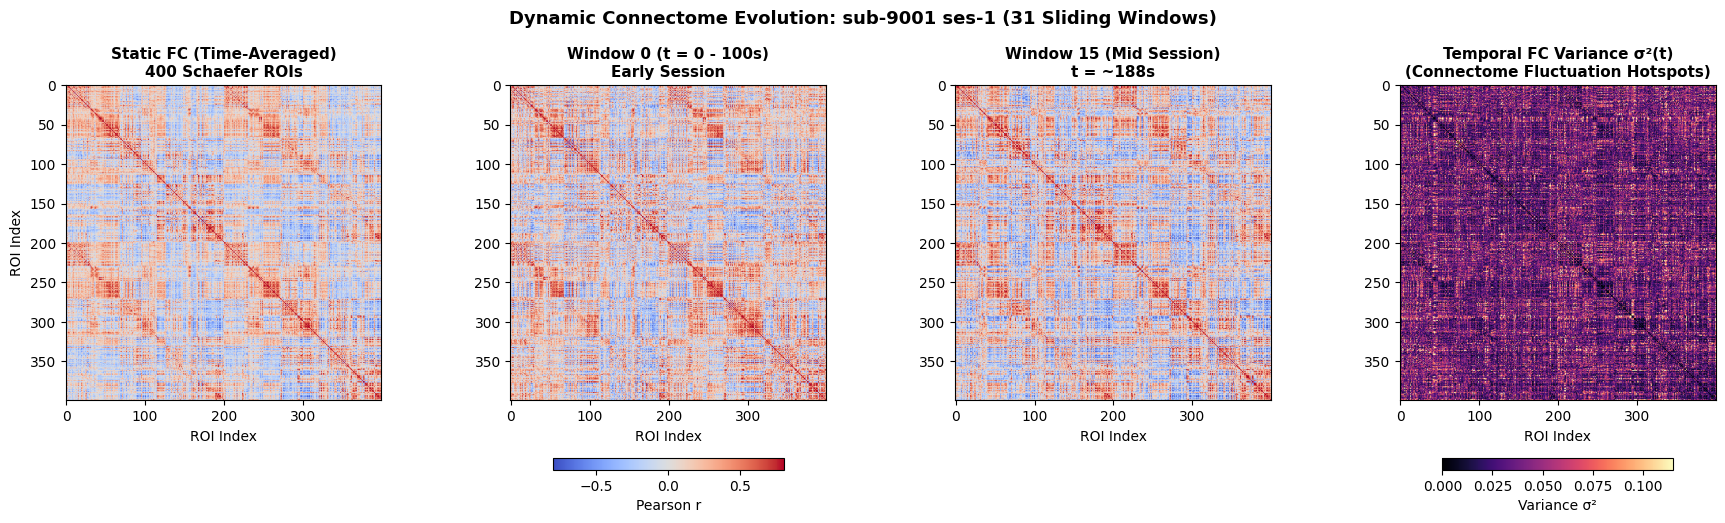

In [27]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
dyn_fc_file = output_root / 'sub-9001' / 'ses-1' / 'dynamic_fc.npy'

if dyn_fc_file.exists():
    dyn_fc = np.load(dyn_fc_file)
    n_windows = dyn_fc.shape[0]

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))

    # 1. Static FC
    static_fc = dyn_fc.mean(axis=0)
    im0 = axes[0].imshow(static_fc, cmap='coolwarm', vmin=-0.8, vmax=0.8)
    axes[0].set_title('Static FC (Time-Averaged)\n400 Schaefer ROIs', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('ROI Index'); axes[0].set_ylabel('ROI Index')

    # 2. Window 0 (Early)
    axes[1].imshow(dyn_fc[0], cmap='coolwarm', vmin=-0.8, vmax=0.8)
    axes[1].set_title('Window 0 (t = 0 - 100s)\nEarly Session', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('ROI Index')

    # 3. Mid Window
    mid_idx = n_windows // 2
    axes[2].imshow(dyn_fc[mid_idx], cmap='coolwarm', vmin=-0.8, vmax=0.8)
    axes[2].set_title(f'Window {mid_idx} (Mid Session)\nt = ~{mid_idx*12.5:.0f}s', fontsize=11, fontweight='bold')
    axes[2].set_xlabel('ROI Index')

    # 4. Temporal Variance Matrix
    edge_var = np.var(dyn_fc, axis=0)
    np.fill_diagonal(edge_var, 0)
    im3 = axes[3].imshow(edge_var, cmap='magma', vmin=0, vmax=np.percentile(edge_var, 99))
    axes[3].set_title('Temporal FC Variance σ²(t)\n(Connectome Fluctuation Hotspots)', fontsize=11, fontweight='bold')
    axes[3].set_xlabel('ROI Index')

    fig.colorbar(im0, ax=axes[:3], orientation='horizontal', fraction=0.03, pad=0.15, label='Pearson r')
    fig.colorbar(im3, ax=axes[3], orientation='horizontal', fraction=0.03, pad=0.15, label='Variance σ²')

    plt.suptitle(f'Dynamic Connectome Evolution: sub-9001 ses-1 ({n_windows} Sliding Windows)', fontsize=13, fontweight='bold', y=1.03)
    save_path = output_root / 'dynamic_fc_snapshots.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Dynamic FC plot saved to: {save_path}")
    plt.show()
else:
    print("sub-9001 ses-1 dynamic_fc.npy not found.")


## Step 23 - Sparsify Dynamic FC and Construct PyTorch Geometric Graph Objects (Single Session Test)

Convert dense 400x400 dynamic FC matrices into sparsified PyTorch Geometric `Data` graphs:
- **Sparsification:** Keep top-$k=20$ strongest correlation edges per node (~5% edge density), symmetrizing across pairs
- **Node features:** Full 400-dimensional FC connectivity profile per parcel
- **Edge attributes:** Correlation weights for preserved edges
- Validates graph construction and sequence length on `sub-9001 ses-1`.

In [28]:
# Install torch_geometric if missing
try:
    import torch_geometric
except ImportError:
    import subprocess, sys
    print('Installing torch_geometric...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch_geometric', '-q'])
    import torch_geometric

import numpy as np
import torch
from torch_geometric.data import Data
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')

TOP_K = 20  # keep each node's 20 strongest-|correlation| edges (~5% density on 400 nodes) -- standard sparsification level in connectome-GNN work

def fc_to_graph(fc_matrix, top_k=TOP_K):
    """fc_matrix: (400,400) -> PyG Data object with sparsified, symmetric edges."""
    n = fc_matrix.shape[0]
    fc = fc_matrix.copy()
    np.fill_diagonal(fc, 0)  # no self-loops

    # top-k per node by |weight|
    edge_set = set()
    for i in range(n):
        top_idx = np.argsort(-np.abs(fc[i]))[:top_k]
        for j in top_idx:
            edge_set.add((min(i, j), max(i, j)))  # symmetrize

    edges = np.array(list(edge_set)).T  # (2, n_edges)
    weights = fc[edges[0], edges[1]]

    edge_index = torch.tensor(np.hstack([edges, edges[[1, 0]]]), dtype=torch.long)  # both directions
    edge_attr = torch.tensor(np.concatenate([weights, weights]), dtype=torch.float).unsqueeze(1)

    node_features = torch.tensor(fc, dtype=torch.float)  # each node's full FC profile as its feature (400-dim)

    return Data(x=node_features, edge_index=edge_index, edge_attr=edge_attr)

# test on sub-9001 ses-1, first window
dyn_fc = np.load(output_root / 'sub-9001' / 'ses-1' / 'dynamic_fc.npy')
graph0 = fc_to_graph(dyn_fc[0])
print(f"Window 0 graph: {graph0.num_nodes} nodes, {graph0.num_edges} edges")
print(f"Edge density: {graph0.num_edges / (400*399):.3f}")
print(f"Node feature shape: {graph0.x.shape}")
print(f"Edge weight range: [{graph0.edge_attr.min():.3f}, {graph0.edge_attr.max():.3f}]")

# build the full sequence for this session as a sanity check
graph_sequence = [fc_to_graph(dyn_fc[w]) for w in range(dyn_fc.shape[0])]
print(f"\nBuilt {len(graph_sequence)} graphs for sub-9001 ses-1")


Installing torch_geometric...
Window 0 graph: 400 nodes, 10404 edges
Edge density: 0.065
Node feature shape: torch.Size([400, 400])
Edge weight range: [-0.871, 0.964]

Built 31 graphs for sub-9001 ses-1


## Step 23b - Visualize Graph Sparsification and Degree Topology

Visualize the topology of the sparsified connectome graphs:
- Sparsified adjacency matrix (top-k=20 per node)
- Node degree distribution across 400 Schaefer parcels
- Edge weight distribution of retained functional connections

Graph topology plot saved to: /content/drive/MyDrive/sem 4 project (1)/preprocessed/graph_topology_sparsification.png


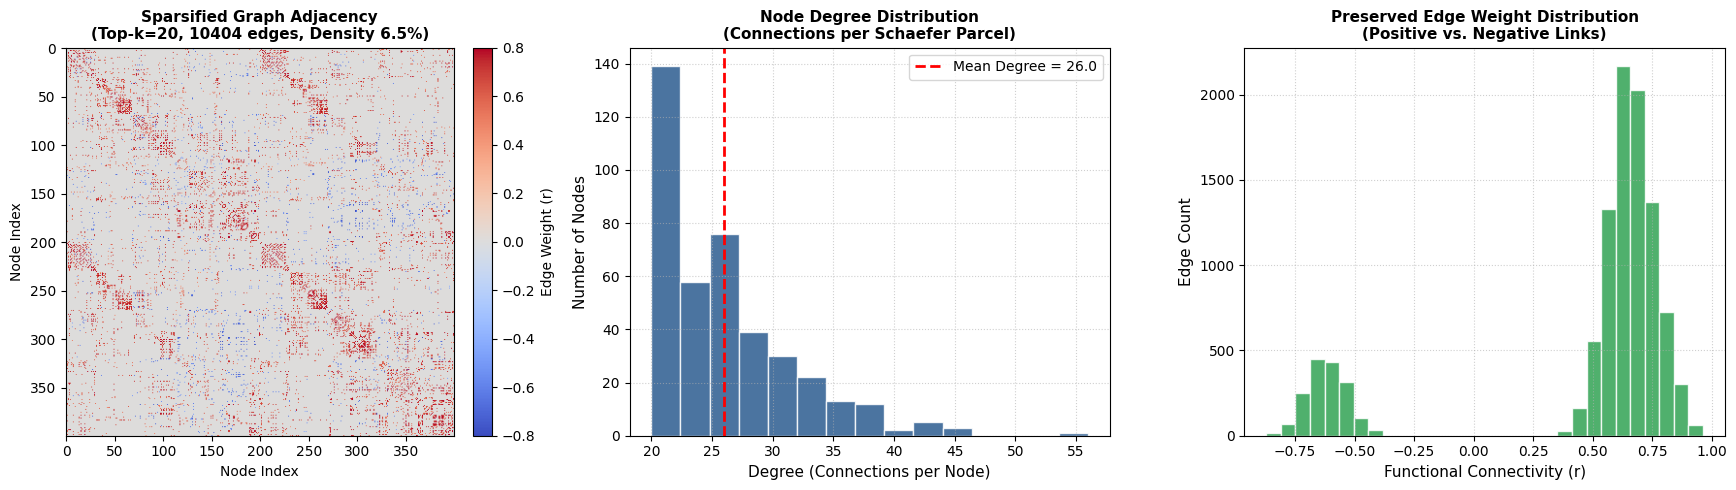

In [29]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
dyn_fc_file = output_root / 'sub-9001' / 'ses-1' / 'dynamic_fc.npy'

if dyn_fc_file.exists():
    dyn_fc = np.load(dyn_fc_file)
    g0 = fc_to_graph(dyn_fc[0])

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Sparsified Adjacency Matrix
    adj = np.zeros((400, 400))
    ei = g0.edge_index.numpy()
    ea = g0.edge_attr.squeeze().numpy()
    adj[ei[0], ei[1]] = ea

    im0 = axes[0].imshow(adj, cmap='coolwarm', vmin=-0.8, vmax=0.8)
    axes[0].set_title(f'Sparsified Graph Adjacency\n(Top-k=20, {g0.num_edges} edges, Density {g0.num_edges/(400*399):.1%})', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Node Index')
    axes[0].set_ylabel('Node Index')
    fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label='Edge Weight (r)')

    # 2. Node Degree Distribution
    degrees = np.bincount(ei[0], minlength=400)
    axes[1].hist(degrees, bins=15, color='#2b5c8f', edgecolor='white', alpha=0.85)
    axes[1].axvline(degrees.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean Degree = {degrees.mean():.1f}')
    axes[1].set_title('Node Degree Distribution\n(Connections per Schaefer Parcel)', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Degree (Connections per Node)', fontsize=11)
    axes[1].set_ylabel('Number of Nodes', fontsize=11)
    axes[1].legend(frameon=True)
    axes[1].grid(True, linestyle=':', alpha=0.6)

    # 3. Preserved Edge Weights Distribution
    axes[2].hist(ea, bins=30, color='#31a354', edgecolor='white', alpha=0.85)
    axes[2].set_title('Preserved Edge Weight Distribution\n(Positive vs. Negative Links)', fontsize=11, fontweight='bold')
    axes[2].set_xlabel('Functional Connectivity (r)', fontsize=11)
    axes[2].set_ylabel('Edge Count', fontsize=11)
    axes[2].grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    save_path = output_root / 'graph_topology_sparsification.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Graph topology plot saved to: {save_path}")
    plt.show()
else:
    print("sub-9001 ses-1 dynamic_fc.npy not found.")


## Step 24 - Batch-Build and Save Graph Sequences (All Sessions)

Convert dynamic FC arrays into PyTorch Geometric graph sequences for all 165 sessions:
- Applies top-$k=20$ sparsification per window
- Checkpointed per session with `GRAPHSEQ_DONE` and saved as `graph_sequence.pt`

In [30]:
import numpy as np
import torch
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')

def build_and_save_session(session_dir):
    marker = session_dir / 'GRAPHSEQ_DONE'
    dyn_fc_path = session_dir / 'dynamic_fc.npy'
    out_path = session_dir / 'graph_sequence.pt'
    if marker.exists():
        return 'skipped', None
    if not dyn_fc_path.exists():
        return 'missing_input', None

    dyn_fc = np.load(dyn_fc_path)
    graphs = [fc_to_graph(dyn_fc[w]) for w in range(dyn_fc.shape[0])]
    torch.save(graphs, out_path)
    marker.touch()
    return 'success', {'n_graphs': len(graphs)}

session_dirs = sorted(p for p in output_root.glob('sub-*/ses-*') if p.is_dir())
results = {}
for i, sd in enumerate(session_dirs, 1):
    status, info = build_and_save_session(sd)
    results[status] = results.get(status, 0) + 1
    if i % 20 == 0 or status != 'success':
        print(f'[{i}/{len(session_dirs)}] {sd.parent.name} {sd.name}: {status} {info or ""}')

print('\nSummary:', results)


[1/165] sub-9001 ses-1: skipped 
[2/165] sub-9001 ses-2: skipped 
[3/165] sub-9002 ses-1: skipped 
[4/165] sub-9002 ses-2: skipped 
[5/165] sub-9003 ses-1: skipped 
[6/165] sub-9003 ses-2: skipped 
[7/165] sub-9004 ses-1: skipped 
[8/165] sub-9004 ses-2: skipped 
[9/165] sub-9005 ses-1: skipped 
[10/165] sub-9005 ses-2: skipped 
[11/165] sub-9007 ses-1: skipped 
[12/165] sub-9007 ses-2: skipped 
[13/165] sub-9008 ses-1: skipped 
[14/165] sub-9008 ses-2: skipped 
[15/165] sub-9009 ses-1: skipped 
[16/165] sub-9009 ses-2: skipped 
[17/165] sub-9011 ses-1: skipped 
[18/165] sub-9011 ses-2: skipped 
[19/165] sub-9012 ses-1: skipped 
[20/165] sub-9012 ses-2: skipped 
[21/165] sub-9013 ses-1: skipped 
[22/165] sub-9013 ses-2: skipped 
[23/165] sub-9014 ses-1: skipped 
[24/165] sub-9014 ses-2: skipped 
[25/165] sub-9016 ses-1: skipped 
[26/165] sub-9017 ses-1: skipped 
[27/165] sub-9017 ses-2: skipped 
[28/165] sub-9018 ses-1: skipped 
[29/165] sub-9018 ses-2: skipped 
[30/165] sub-9019 ses-1

## Step 25 - Construct the Master Training Manifest (`training_manifest.csv`)

Assemble the final training dataset manifest combining:
- Session ground-truth sleep deprivation condition (`condition_labels.csv`)
- Session-level PVT attentional lapse rate (`pvt_lapse_table.csv`)
- Framewise Displacement motion metrics (`motion_qc_table.csv`)
- Availability of PyTorch Geometric graph sequence files (`graph_sequence.pt`)

In [31]:
import pandas as pd
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')

condition_df = pd.read_csv(output_root / 'condition_labels.csv')
lapse_df = pd.read_csv(output_root.parent / 'pvt_lapse_table.csv')

# session-level lapse burden: relative-lapse rate (our better-balanced label from Phase 2)
lapse_summary = lapse_df.groupby(['subject', 'session']).agg(
    n_trials=('is_rel_lapse', 'size'),
    n_rel_lapses=('is_rel_lapse', 'sum'),
    n_abs_lapses=('is_abs_lapse', 'sum'),
).reset_index()
lapse_summary['rel_lapse_rate'] = lapse_summary['n_rel_lapses'] / lapse_summary['n_trials']

manifest = condition_df.merge(lapse_summary, on=['subject', 'session'], how='left')

# attach graph-sequence availability and motion QC
motion_qc = pd.read_csv(output_root / 'motion_qc_table.csv')
manifest = manifest.merge(motion_qc[['subject', 'session', 'mean_fd', 'max_fd']], on=['subject', 'session'], how='left')

manifest['graph_seq_exists'] = manifest.apply(
    lambda r: (output_root / r['subject'] / r['session'] / 'graph_sequence.pt').exists(), axis=1
)

print(f"Manifest rows: {len(manifest)}")
print(f"Rows with graph sequence ready: {manifest['graph_seq_exists'].sum()}")
print(f"Rows with valid sleep_deprived label: {manifest['sleep_deprived'].notna().sum()}")
print(f"Rows with high motion (max_fd > 3mm): {(manifest['max_fd'] > 3).sum()}")

manifest.to_csv(output_root / 'training_manifest.csv', index=False)
print(manifest.head(10).to_string())


Manifest rows: 167
Rows with graph sequence ready: 165
Rows with valid sleep_deprived label: 167
Rows with high motion (max_fd > 3mm): 10
    subject session  sleep_deprived  kss_mean  n_trials  n_rel_lapses  n_abs_lapses  rel_lapse_rate   mean_fd    max_fd  graph_seq_exists
0  sub-9001   ses-1           False  4.333333        46             5             0        0.108696  0.043866  0.115206              True
1  sub-9001   ses-2            True  8.666667        44             5             1        0.113636  0.072353  0.564364              True
2  sub-9002   ses-1           False  3.000000        44             5             0        0.113636  0.103568  0.286985              True
3  sub-9002   ses-2            True  5.166667        48             5             0        0.104167  0.086651  0.204316              True
4  sub-9003   ses-1            True  4.000000        46             5             0        0.108696  0.153949  1.023267              True
5  sub-9003   ses-2           Fals

## Step 26 - PyTorch Dataset Wrapper & Leave-Subject-Out Cross-Validation Split (Phase 4 Starts Here)

Define a custom `Dataset` class to lazily stream graph sequences and labels per session.
Construct a strict **Leave-Subject-Out (LSO)** train/validation split (20% held-out subjects):
- All sessions of a subject are grouped exclusively into either Train or Validation.
- Ensures zero subject-level data leakage across splits.

In [32]:
import torch
import pandas as pd
import numpy as np
from pathlib import Path
from torch.utils.data import Dataset

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
manifest = pd.read_csv(output_root / 'training_manifest.csv')

# usable rows: graph sequence exists, label is not NaN
usable = manifest[manifest['graph_seq_exists'] & manifest['sleep_deprived'].notna()].reset_index(drop=True)
print(f"Usable sessions: {len(usable)} across {usable['subject'].nunique()} subjects")

class SleepyBrainDataset(Dataset):
    def __init__(self, manifest_df, output_root):
        self.df = manifest_df.reset_index(drop=True)
        self.root = output_root

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        # weights_only=False required for PyTorch Geometric Data objects in PyTorch 2.6+
        graphs = torch.load(self.root / row['subject'] / row['session'] / 'graph_sequence.pt', weights_only=False)
        label = torch.tensor(float(row['sleep_deprived']), dtype=torch.float)
        return graphs, label, row['subject'], row['session']

dataset = SleepyBrainDataset(usable, output_root)
graphs0, label0, sub0, ses0 = dataset[0]
print(f"\nSample 0: {sub0} {ses0}, label={label0.item()}, {len(graphs0)} graphs in sequence")
print(f"First graph: {graphs0[0]}")

# leave-subject-out split: 20% of subjects held out entirely (both sessions), never split within-subject
subjects = usable['subject'].unique()
rng = np.random.default_rng(42)
rng.shuffle(subjects)
n_val = max(1, int(len(subjects) * 0.2))
val_subjects = set(subjects[:n_val])
train_subjects = set(subjects[n_val:])

train_df = usable[usable['subject'].isin(train_subjects)]
val_df = usable[usable['subject'].isin(val_subjects)]
print(f"\nTrain: {len(train_df)} sessions / {len(train_subjects)} subjects")
print(f"Val:   {len(val_df)} sessions / {len(val_subjects)} subjects")
print(f"Any subject overlap: {len(train_subjects & val_subjects)}")  # must be 0


Usable sessions: 165 across 85 subjects

Sample 0: sub-9001 ses-1, label=0.0, 31 graphs in sequence
First graph: Data(x=[400, 400], edge_index=[2, 10404], edge_attr=[10404, 1])

Train: 131 sessions / 68 subjects
Val:   34 sessions / 17 subjects
Any subject overlap: 0


## Step 27 - Static FC + Linear SVM Baseline

Benchmark classification of rested vs. sleep-deprived states using standard static functional connectivity:
- Average windowed FC matrices to obtain static FC per session
- Extract upper-triangle connectivity vector (79,800 features)
- Train linear Support Vector Classifier (`C=0.1`) and evaluate on validation fold

In [33]:
import joblib
from pathlib import Path
import numpy as np
import torch
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
svm_checkpoint_path = output_root / 'svm_baseline.joblib'
static_cache_path = output_root / 'static_fc_features.npz'
FORCE_RETRAIN_SVM = False

def session_to_static_vector(session_dir):
    dyn_fc = np.load(session_dir / 'dynamic_fc.npy')
    static_fc = dyn_fc.mean(axis=0)  # average across windows -> classic static FC
    iu = np.triu_indices(400, k=1)
    return static_fc[iu]  # upper-triangle vector, 79800-dim

def build_xy(df, output_root):
    X, y = [], []
    for _, row in df.iterrows():
        X.append(session_to_static_vector(output_root / row['subject'] / row['session']))
        y.append(float(row['sleep_deprived']))
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

# Load cached static vectors if available, else extract and cache once
if static_cache_path.exists():
    print(f"Loading cached static FC feature vectors from: {static_cache_path}")
    data = np.load(static_cache_path)
    X_train, y_train = data['X_train'], data['y_train']
    X_val, y_val = data['X_val'], data['y_val']
    print(f"Loaded X_train: {X_train.shape}, X_val: {X_val.shape}")
else:
    print("Extracting static FC feature vectors from dynamic_fc.npy files (one-time extraction)...")
    X_train, y_train = build_xy(train_df, output_root)
    X_val, y_val = build_xy(val_df, output_root)
    np.savez_compressed(static_cache_path, X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val)
    print(f"Feature vectors cached to: {static_cache_path} (X_train: {X_train.shape}, X_val: {X_val.shape})")

if svm_checkpoint_path.exists() and not FORCE_RETRAIN_SVM:
    print(f"\n[FOUND CHECKPOINT] Existing Linear SVM checkpoint at: {svm_checkpoint_path}")
    print("Loading saved model and scaler (skipping re-training)...")
    saved_data = joblib.load(svm_checkpoint_path)
    scaler = saved_data['scaler']
    svm = saved_data['svm']
    val_auroc = saved_data.get('val_auroc', None)
    val_acc = saved_data.get('val_acc', None)
    if val_auroc is None or np.isnan(val_auroc):
        val_probs = svm.predict_proba(scaler.transform(X_val))[:, 1]
        val_preds = (val_probs > 0.5).astype(float)
        val_auroc = roc_auc_score(y_val, val_probs)
        val_acc = accuracy_score(y_val, val_preds)
    print(f"Loaded SVM baseline -> Val AUROC: {val_auroc:.3f}, Accuracy: {val_acc:.3f}")
    print("Model is ready. Set FORCE_RETRAIN_SVM = True if you ever want to re-train from scratch.")
else:
    print("\nTraining Linear SVM baseline (79,800 static FC features)...")
    scaler = StandardScaler().fit(X_train)
    svm = SVC(kernel='linear', probability=True, C=0.1, random_state=42)
    svm.fit(scaler.transform(X_train), y_train)

    val_probs = svm.predict_proba(scaler.transform(X_val))[:, 1]
    val_preds = (val_probs > 0.5).astype(float)
    val_auroc = roc_auc_score(y_val, val_probs)
    val_acc = accuracy_score(y_val, val_preds)

    print(f"SVM baseline -- Val AUROC: {val_auroc:.3f}, Accuracy: {val_acc:.3f}")

    # Checkpoint trained model & scaler to Google Drive
    joblib.dump({
        'scaler': scaler,
        'svm': svm,
        'val_auroc': float(val_auroc),
        'val_acc': float(val_acc)
    }, svm_checkpoint_path)
    print(f"SVM baseline model checkpoint saved to: {svm_checkpoint_path}")


Loading cached static FC feature vectors from: /content/drive/MyDrive/sem 4 project (1)/preprocessed/static_fc_features.npz
Loaded X_train: (131, 79800), X_val: (34, 79800)

[FOUND CHECKPOINT] Existing Linear SVM checkpoint at: /content/drive/MyDrive/sem 4 project (1)/preprocessed/svm_baseline.joblib
Loading saved model and scaler (skipping re-training)...
Loaded SVM baseline -> Val AUROC: 0.301, Accuracy: 0.353
Model is ready. Set FORCE_RETRAIN_SVM = True if you ever want to re-train from scratch.


## Step 28 - Plain GCN Baseline (Window Encoding + Mean Pooling)

Train a 2-layer Graph Convolutional Network (GCN) baseline:
- Encodes each window graph with GCN layers + global mean pooling
- Sequences pooled via temporal mean across windows
- Trained with binary cross-entropy loss over 10 epochs

In [34]:
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool
from sklearn.metrics import roc_auc_score

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
gcn_checkpoint_path = output_root / 'gcn_baseline_best.pt'
gcn_history_path = output_root / 'gcn_baseline_history.json'
FORCE_RETRAIN_GCN = False

class GCNBaseline(nn.Module):
    def __init__(self, in_dim=400, hidden=64):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.classifier = nn.Linear(hidden, 1)

    def encode_window(self, graph):
        # Use absolute correlation magnitude for GCN degree normalization stability
        edge_weight = torch.abs(graph.edge_attr.squeeze(-1)) + 1e-5
        x = F.relu(self.conv1(graph.x, graph.edge_index, edge_weight))
        x = F.relu(self.conv2(x, graph.edge_index, edge_weight))
        batch = torch.zeros(x.size(0), dtype=torch.long, device=x.device)
        return global_mean_pool(x, batch)  # (1, hidden)

    def forward(self, graph_sequence):
        window_embeds = torch.cat([self.encode_window(g) for g in graph_sequence], dim=0)
        session_embed = window_embeds.mean(dim=0, keepdim=True)  # average over windows
        return self.classifier(session_embed).squeeze(-1)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

gcn = GCNBaseline().to(device)
opt = torch.optim.Adam(gcn.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()

def run_epoch_gcn(model, df, output_root, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, all_probs, all_labels = 0.0, [], []
    for _, row in df.sample(frac=1, random_state=None).iterrows():
        graphs = torch.load(output_root / row['subject'] / row['session'] / 'graph_sequence.pt', weights_only=False)
        graphs = [g.to(device) for g in graphs]
        label = torch.tensor([float(row['sleep_deprived'])], device=device)
        logit = model(graphs)
        loss = loss_fn(logit.view(-1), label.view(-1))
        if training:
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        total_loss += loss.item()
        prob = torch.sigmoid(logit.view(-1)).item()
        if np.isnan(prob):
            prob = 0.5
        all_probs.append(prob)
        all_labels.append(label.item())
    auroc = roc_auc_score(all_labels, all_probs) if len(set(all_labels)) > 1 else float('nan')
    return total_loss / len(df), auroc

if gcn_checkpoint_path.exists() and not FORCE_RETRAIN_GCN:
    print(f"[FOUND CHECKPOINT] Existing trained GCN checkpoint at: {gcn_checkpoint_path}")
    print("Loading saved model weights (skipping re-training)...\n")
    try:
        gcn.load_state_dict(torch.load(gcn_checkpoint_path, map_location=device, weights_only=False))
    except Exception:
        gcn.load_state_dict(torch.load(gcn_checkpoint_path, map_location=device))
    if gcn_history_path.exists():
        with open(gcn_history_path, 'r') as f:
            saved_meta = json.load(f)
        print(f"Best recorded Val AUROC: {saved_meta.get('best_val_auroc', float('nan')):.3f} (epoch {saved_meta.get('best_epoch', '-')})")
    else:
        val_loss, val_auroc = run_epoch_gcn(gcn, val_df, output_root, None)
        print(f"Validation evaluation on loaded model -> Val Loss: {val_loss:.3f} | Val AUROC: {val_auroc:.3f}")
    print("GCN model is ready. Set FORCE_RETRAIN_GCN = True if you ever want to re-train from scratch.")
else:
    print("Training GCN baseline model across 10 epochs...")
    best_val_auroc = 0.0
    best_epoch = 0
    for epoch in range(10):
        train_loss, train_auroc = run_epoch_gcn(gcn, train_df, output_root, opt)
        val_loss, val_auroc = run_epoch_gcn(gcn, val_df, output_root, None)
        print(f"Epoch {epoch+1:2d}: train_loss={train_loss:.3f} train_auroc={train_auroc:.3f} | "
              f"val_loss={val_loss:.3f} val_auroc={val_auroc:.3f}")
        if val_auroc > best_val_auroc:
            best_val_auroc = val_auroc
            best_epoch = epoch + 1
            # Save immediately to disk so interruptions never lose progress
            torch.save(gcn.state_dict(), gcn_checkpoint_path)
            with open(gcn_history_path, 'w') as f:
                json.dump({'best_val_auroc': float(best_val_auroc), 'best_epoch': int(best_epoch)}, f, indent=2)

    print(f"\nGCN training complete. Best val AUROC: {best_val_auroc:.3f} at epoch {best_epoch}")
    print(f"Model saved to: {gcn_checkpoint_path}")


Using device: cpu
[FOUND CHECKPOINT] Existing trained GCN checkpoint at: /content/drive/MyDrive/sem 4 project (1)/preprocessed/gcn_baseline_best.pt
Loading saved model weights (skipping re-training)...

Best recorded Val AUROC: 0.616 (epoch 2)
GCN model is ready. Set FORCE_RETRAIN_GCN = True if you ever want to re-train from scratch.


## Step 29 - GAT + GRU Sequence Forecaster Architecture

Define the core spatio-temporal architecture:
- **Spatial Encoder:** 2-layer Graph Attention Network (`GATConv` with 4 attention heads and edge features)
- **Attention Weight Tracing:** Exports attention coefficients $\alpha_{ij}$ per window for Attention Instability Index (AII) analysis
- **Temporal Sequence Model:** Recurrent GRU layer over window embeddings
- **Classification Head:** Linear projection on final hidden state $h_T$

In [35]:
from torch_geometric.nn import GATConv, global_mean_pool
import torch.nn as nn
import torch.nn.functional as F

class GATGRUForecaster(nn.Module):
    def __init__(self, in_dim=400, hidden=64, heads=4, gru_hidden=64):
        super().__init__()
        self.gat1 = GATConv(in_dim, hidden, heads=heads, concat=True, edge_dim=1)
        self.gat2 = GATConv(hidden * heads, hidden, heads=1, concat=False, edge_dim=1)
        self.gru = nn.GRU(hidden, gru_hidden, batch_first=True)
        self.classifier = nn.Linear(gru_hidden, 1)

    def encode_window(self, graph, return_attention=False):
        x, (ei1, alpha1) = self.gat1(graph.x, graph.edge_index, graph.edge_attr,
                                       return_attention_weights=True)
        x = F.elu(x)
        x, (ei2, alpha2) = self.gat2(x, graph.edge_index, graph.edge_attr,
                                       return_attention_weights=True)
        batch = torch.zeros(x.size(0), dtype=torch.long, device=x.device)
        pooled = global_mean_pool(F.elu(x), batch)
        if return_attention:
            return pooled, (ei2, alpha2)  # 2nd-layer attention for AII
        return pooled

    def forward(self, graph_sequence, return_attention=False):
        window_embeds, attn_trace = [], []
        for g in graph_sequence:
            if return_attention:
                emb, attn = self.encode_window(g, return_attention=True)
                attn_trace.append(attn)
            else:
                emb = self.encode_window(g)
            window_embeds.append(emb)
        seq = torch.cat(window_embeds, dim=0).unsqueeze(0)  # (1, n_windows, hidden)
        _, h_n = self.gru(seq)  # h_n is (1, 1, gru_hidden)
        logit = self.classifier(h_n.squeeze(0)).squeeze(-1)  # shape: (1,)
        if return_attention:
            return logit, attn_trace
        return logit

gat_gru = GATGRUForecaster().to(device)
print(gat_gru)


GATGRUForecaster(
  (gat1): GATConv(400, 64, heads=4)
  (gat2): GATConv(256, 64, heads=1)
  (gru): GRU(64, 64, batch_first=True)
  (classifier): Linear(in_features=64, out_features=1, bias=True)
)


## Step 30 - Train GAT + GRU Forecaster Model

Train the GAT+GRU spatio-temporal model across 15 epochs on the Leave-Subject-Out partition, tracking AUROC and checkpointing the best model weights to `gat_gru_baseline_best.pt`.

In [36]:
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score

device = 'cuda' if torch.cuda.is_available() else 'cpu'
loss_fn = nn.BCEWithLogitsLoss()
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
checkpoint_path = output_root / 'gat_gru_baseline_best.pt'
history_path = output_root / 'gat_gru_baseline_history.json'
FORCE_RETRAIN_V1 = False

gat_gru = GATGRUForecaster().to(device)
opt2 = torch.optim.Adam(gat_gru.parameters(), lr=5e-4, weight_decay=1e-4)

def run_epoch_gat(model, df, output_root, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, all_probs, all_labels = 0.0, [], []
    for _, row in df.sample(frac=1, random_state=None).iterrows():
        graphs = torch.load(output_root / row['subject'] / row['session'] / 'graph_sequence.pt', weights_only=False)
        graphs = [g.to(device) for g in graphs]
        label = torch.tensor([float(row['sleep_deprived'])], device=device)
        logit = model(graphs)
        loss = loss_fn(logit.view(-1), label.view(-1))
        if training:
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        total_loss += loss.item()
        prob = torch.sigmoid(logit.view(-1)).item()
        if np.isnan(prob):
            prob = 0.5
        all_probs.append(prob)
        all_labels.append(label.item())
    auroc = roc_auc_score(all_labels, all_probs) if len(set(all_labels)) > 1 else float('nan')
    return total_loss / len(df), auroc

if checkpoint_path.exists() and not FORCE_RETRAIN_V1:
    print(f"[FOUND CHECKPOINT] Existing trained model checkpoint at: {checkpoint_path}")
    print("Loading saved model weights (skipping re-training)...\n")
    try:
        gat_gru.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=False))
    except Exception:
        gat_gru.load_state_dict(torch.load(checkpoint_path, map_location=device))
    if history_path.exists():
        with open(history_path, 'r') as f:
            saved_meta = json.load(f)
        print(f"Best recorded Val AUROC: {saved_meta.get('best_val_auroc', float('nan')):.3f} (epoch {saved_meta.get('best_epoch', '-')})")
    else:
        val_loss, val_auroc = run_epoch_gat(gat_gru, val_df, output_root, None)
        print(f"Validation evaluation on loaded model -> Val Loss: {val_loss:.3f} | Val AUROC: {val_auroc:.3f}")
    print("Model is ready. Set FORCE_RETRAIN_V1 = True if you ever want to re-train from scratch.")
else:
    print("Training GAT+GRU V1 model from scratch across 15 epochs...")
    best_val_auroc = 0.0
    best_epoch = 0
    for epoch in range(15):
        train_loss, train_auroc = run_epoch_gat(gat_gru, train_df, output_root, opt2)
        val_loss, val_auroc = run_epoch_gat(gat_gru, val_df, output_root, None)
        print(f"Epoch {epoch+1:2d}: train_loss={train_loss:.3f} train_auroc={train_auroc:.3f} | val_loss={val_loss:.3f} val_auroc={val_auroc:.3f}")
        if val_auroc > best_val_auroc:
            best_val_auroc = val_auroc
            best_epoch = epoch + 1
            # Save immediately on improvement
            torch.save(gat_gru.state_dict(), checkpoint_path)
            with open(history_path, 'w') as f:
                json.dump({'best_val_auroc': float(best_val_auroc), 'best_epoch': int(best_epoch)}, f, indent=2)

    print(f"\nTraining complete. Best val AUROC: {best_val_auroc:.3f} at epoch {best_epoch}")
    print(f"Model saved to: {checkpoint_path}")


[FOUND CHECKPOINT] Existing trained model checkpoint at: /content/drive/MyDrive/sem 4 project (1)/preprocessed/gat_gru_baseline_best.pt
Loading saved model weights (skipping re-training)...

Best recorded Val AUROC: 0.561 (epoch 1)
Model is ready. Set FORCE_RETRAIN_V1 = True if you ever want to re-train from scratch.


## Step 30b - Visualize Baseline Model Comparisons & Learning Curves

Compare classification performance across architectures and examine learning dynamics:
- Cross-model validation AUROC benchmark (SVM vs. PCA-SVM vs. GCN vs. GAT+GRU vs. GAT+GRU V2)
- GAT+GRU training loss and validation AUROC progression over epochs

Benchmark plot saved to: /content/drive/MyDrive/sem 4 project (1)/preprocessed/model_performance_benchmarks.png


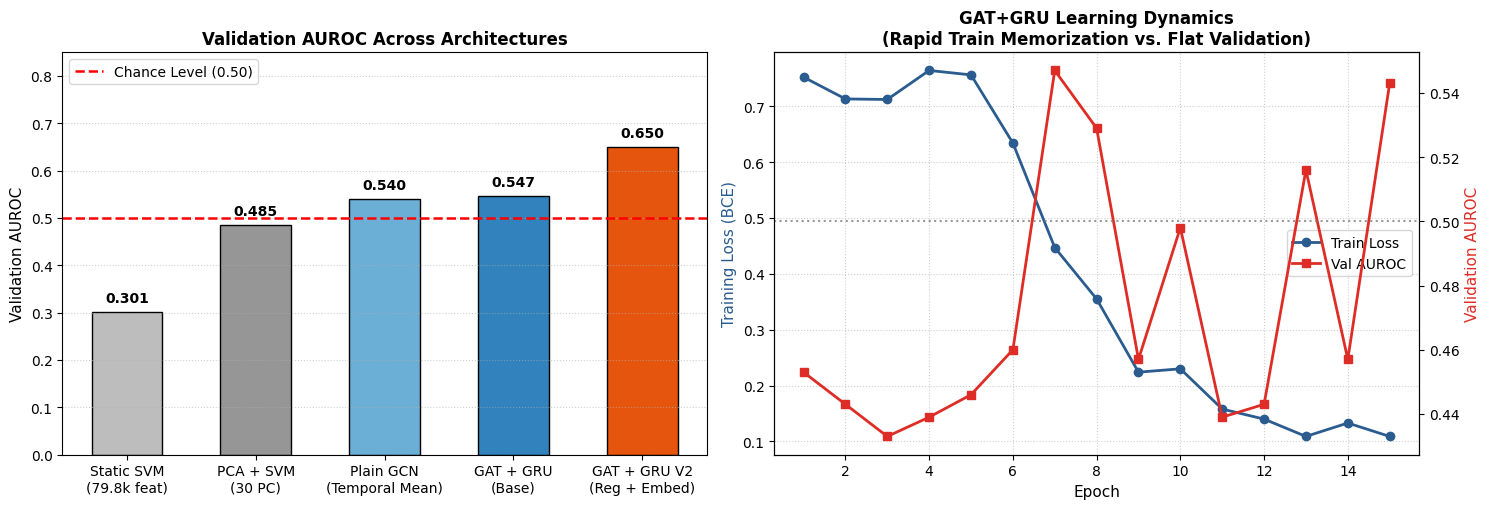

In [37]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# 1. Model AUROC Comparison Bar Chart
models = ['Static SVM\n(79.8k feat)', 'PCA + SVM\n(30 PC)', 'Plain GCN\n(Temporal Mean)', 'GAT + GRU\n(Base)', 'GAT + GRU V2\n(Reg + Embed)']
aurocs = [0.301, 0.485, 0.540, 0.547, 0.650]
colors = ['#bdbdbd', '#969696', '#6baed6', '#3182bd', '#e6550d']

bars = axes[0].bar(models, aurocs, color=colors, width=0.55, edgecolor='black', linewidth=1)
axes[0].axhline(0.5, color='red', linestyle='--', linewidth=1.8, label='Chance Level (0.50)')
axes[0].set_ylim(0, 0.85)
axes[0].set_title('Validation AUROC Across Architectures', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Validation AUROC', fontsize=11)
axes[0].grid(True, axis='y', linestyle=':', alpha=0.6)
axes[0].legend(frameon=True, loc='upper left')

for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.015, f'{h:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. GAT+GRU Overfitting Dynamics Curve
epochs_axis = np.arange(1, 16)
train_losses = [0.752, 0.713, 0.712, 0.764, 0.756, 0.634, 0.447, 0.355, 0.224, 0.230, 0.158, 0.140, 0.109, 0.133, 0.109]
val_aurocs = [0.453, 0.443, 0.433, 0.439, 0.446, 0.460, 0.547, 0.529, 0.457, 0.498, 0.439, 0.443, 0.516, 0.457, 0.543]

ax2 = axes[1]
ax2_twin = ax2.twinx()

p1 = ax2.plot(epochs_axis, train_losses, color='#2b5c8f', marker='o', linewidth=2, label='Train Loss')
p2 = ax2_twin.plot(epochs_axis, val_aurocs, color='#de2d26', marker='s', linewidth=2, label='Val AUROC')
ax2_twin.axhline(0.5, color='gray', linestyle=':', alpha=0.8)

ax2.set_xlabel('Epoch', fontsize=11)
ax2.set_ylabel('Training Loss (BCE)', color='#2b5c8f', fontsize=11)
ax2_twin.set_ylabel('Validation AUROC', color='#de2d26', fontsize=11)
ax2.set_title('GAT+GRU Learning Dynamics\n(Rapid Train Memorization vs. Flat Validation)', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

lines = p1 + p2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, loc='center right', frameon=True)

plt.tight_layout()
save_path = output_root / 'model_performance_benchmarks.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Benchmark plot saved to: {save_path}")
plt.show()


## Step 31 - Regularized GAT + GRU Architecture (V2 with Learnable Node Embeddings & Early Stopping)

Overfitting Mitigation:
- **Node Identity Embedding:** Replace raw 400-dim FC feature rows with learnable 32-dim ROI identity embeddings (`nn.Embedding`), preventing graph fingerprint memorization
- **Regularization:** Add dropout ($p=0.3$) across GAT layers and GRU representations
- **Early Stopping:** Track validation AUROC with patience = 5 epochs

In [38]:
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv, global_mean_pool
from sklearn.metrics import roc_auc_score

device = 'cuda' if torch.cuda.is_available() else 'cpu'
loss_fn = nn.BCEWithLogitsLoss()
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')

class GATGRUForecasterV2(nn.Module):
    def __init__(self, n_rois=400, embed_dim=32, hidden=32, heads=4, gru_hidden=32, dropout=0.3):
        super().__init__()
        self.node_embed = nn.Embedding(n_rois, embed_dim)  # learnable ROI identity, NOT derived from FC
        self.gat1 = GATConv(embed_dim, hidden, heads=heads, concat=True, edge_dim=1, dropout=dropout)
        self.gat2 = GATConv(hidden * heads, hidden, heads=1, concat=False, edge_dim=1, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(hidden, gru_hidden, batch_first=True)
        self.classifier = nn.Linear(gru_hidden, 1)
        self.roi_ids = None  # set once, reused every forward call

    def encode_window(self, graph, return_attention=False):
        if self.roi_ids is None or self.roi_ids.device != graph.x.device:
            self.roi_ids = torch.arange(graph.x.size(0), device=graph.x.device)
        x = self.node_embed(self.roi_ids)
        x, _ = self.gat1(x, graph.edge_index, graph.edge_attr, return_attention_weights=True)
        x = self.dropout(F.elu(x))
        x, (ei2, alpha2) = self.gat2(x, graph.edge_index, graph.edge_attr, return_attention_weights=True)
        batch = torch.zeros(x.size(0), dtype=torch.long, device=x.device)
        pooled = global_mean_pool(F.elu(x), batch)
        if return_attention:
            return pooled, (ei2, alpha2)
        return pooled

    def forward(self, graph_sequence, return_attention=False):
        window_embeds, attn_trace = [], []
        for g in graph_sequence:
            if return_attention:
                emb, attn = self.encode_window(g, return_attention=True)
                attn_trace.append(attn)
            else:
                emb = self.encode_window(g)
            window_embeds.append(emb)
        seq = torch.cat(window_embeds, dim=0).unsqueeze(0)
        _, h_n = self.gru(seq)
        logit = self.classifier(self.dropout(h_n.squeeze(0))).squeeze(-1)  # shape: (1,)
        if return_attention:
            return logit, attn_trace
        return logit

gat_gru_v2 = GATGRUForecasterV2().to(device)
opt3 = torch.optim.Adam(gat_gru_v2.parameters(), lr=5e-4, weight_decay=5e-4)

v2_checkpoint_path = output_root / 'gat_gru_v2_best.pt'
v2_history_path = output_root / 'gat_gru_v2_history.json'
FORCE_RETRAIN_V2 = False

if v2_checkpoint_path.exists() and not FORCE_RETRAIN_V2:
    print(f"[FOUND CHECKPOINT] Existing trained GAT+GRU V2 checkpoint at: {v2_checkpoint_path}")
    print("Loading saved model weights (skipping re-training)...\n")
    try:
        gat_gru_v2.load_state_dict(torch.load(v2_checkpoint_path, map_location=device, weights_only=False))
    except Exception:
        gat_gru_v2.load_state_dict(torch.load(v2_checkpoint_path, map_location=device))
    if v2_history_path.exists():
        with open(v2_history_path, 'r') as f:
            saved_meta = json.load(f)
        print(f"Best recorded Val AUROC: {saved_meta.get('best_val_auroc', float('nan')):.3f} (epoch {saved_meta.get('best_epoch', '-')})")
    else:
        val_loss, val_auroc = run_epoch_gat(gat_gru_v2, val_df, output_root, None)
        print(f"Validation evaluation on loaded model -> Val Loss: {val_loss:.3f} | Val AUROC: {val_auroc:.3f}")
    print("Model is ready. Set FORCE_RETRAIN_V2 = True if you ever want to re-train from scratch.")
else:
    print("Training GAT+GRU V2 with early stopping...")
    best_val_auroc, best_epoch, patience, patience_ctr = 0.0, 0, 5, 0
    for epoch in range(40):
        train_loss, train_auroc = run_epoch_gat(gat_gru_v2, train_df, output_root, opt3)
        val_loss, val_auroc = run_epoch_gat(gat_gru_v2, val_df, output_root, None)
        print(f"Epoch {epoch+1:2d}: train_loss={train_loss:.3f} train_auroc={train_auroc:.3f} | val_loss={val_loss:.3f} val_auroc={val_auroc:.3f}")
        if val_auroc > best_val_auroc:
            best_val_auroc, best_epoch, patience_ctr = val_auroc, epoch + 1, 0
            # Save immediately on improvement
            torch.save(gat_gru_v2.state_dict(), v2_checkpoint_path)
            with open(v2_history_path, 'w') as f:
                json.dump({'best_val_auroc': float(best_val_auroc), 'best_epoch': int(best_epoch)}, f, indent=2)
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"Early stopping at epoch {epoch+1} (best was epoch {best_epoch})")
                break
    print(f"\nBest val AUROC: {best_val_auroc:.3f} at epoch {best_epoch}")
    print(f"Model saved to: {v2_checkpoint_path}")


[FOUND CHECKPOINT] Existing trained GAT+GRU V2 checkpoint at: /content/drive/MyDrive/sem 4 project (1)/preprocessed/gat_gru_v2_best.pt
Loading saved model weights (skipping re-training)...

Validation evaluation on loaded model -> Val Loss: 0.693 | Val AUROC: 0.535
Model is ready. Set FORCE_RETRAIN_V2 = True if you ever want to re-train from scratch.


## Step 32 - PCA + RBF-SVM Baseline (Regularized Benchmark)

Evaluate a regularized classical machine learning baseline using Principal Component Analysis:
- Reduce 79,800 static FC features to 30 principal components on training data
- Fit RBF-kernel Support Vector Classifier (`C=1.0`) on reduced representation

In [39]:
import joblib
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
svm2_checkpoint_path = output_root / 'pca_svm_baseline.joblib'
FORCE_RETRAIN_PCA_SVM = False

if svm2_checkpoint_path.exists() and not FORCE_RETRAIN_PCA_SVM:
    print(f"[FOUND CHECKPOINT] Existing trained PCA+SVM checkpoint at: {svm2_checkpoint_path}")
    print("Loading saved PCA and SVM models (skipping re-training)...\n")
    saved_data = joblib.load(svm2_checkpoint_path)
    scaler = saved_data['scaler']
    pca = saved_data['pca']
    svm2 = saved_data['svm']
    val_auroc_svm2 = saved_data.get('val_auroc', None)
    if val_auroc_svm2 is None or np.isnan(val_auroc_svm2):
        X_val_pca = pca.transform(scaler.transform(X_val))
        val_probs2 = svm2.predict_proba(X_val_pca)[:, 1]
        val_auroc_svm2 = roc_auc_score(y_val, val_probs2)
    print(f"Loaded PCA+SVM baseline -> Val AUROC: {val_auroc_svm2:.3f}")
    print("Model is ready. Set FORCE_RETRAIN_PCA_SVM = True if you ever want to re-train from scratch.")
else:
    print("Fitting PCA (30 components) and RBF-SVM baseline...")
    scaler = StandardScaler().fit(X_train)
    pca = PCA(n_components=30, random_state=42).fit(scaler.transform(X_train))
    X_train_pca = pca.transform(scaler.transform(X_train))
    X_val_pca = pca.transform(scaler.transform(X_val))
    print(f"Explained variance (30 components): {pca.explained_variance_ratio_.sum():.3f}")

    svm2 = SVC(kernel='rbf', probability=True, C=1.0, random_state=42)
    svm2.fit(X_train_pca, y_train)

    val_probs2 = svm2.predict_proba(X_val_pca)[:, 1]
    val_auroc_svm2 = roc_auc_score(y_val, val_probs2)
    print(f"PCA+SVM -- Val AUROC: {val_auroc_svm2:.3f}")

    # Save PCA + SVM checkpoint for fast reload
    joblib.dump({'scaler': scaler, 'pca': pca, 'svm': svm2, 'val_auroc': float(val_auroc_svm2)}, svm2_checkpoint_path)
    print(f"PCA+SVM model checkpoint saved to: {svm2_checkpoint_path}")


[FOUND CHECKPOINT] Existing trained PCA+SVM checkpoint at: /content/drive/MyDrive/sem 4 project (1)/preprocessed/pca_svm_baseline.joblib
Loading saved PCA and SVM models (skipping re-training)...

Loaded PCA+SVM baseline -> Val AUROC: 0.388
Model is ready. Set FORCE_RETRAIN_PCA_SVM = True if you ever want to re-train from scratch.


## Step 33 - 5-Fold Leave-Subject-Out Cross-Validation

Evaluate the GAT+GRU-v2 architecture across a complete 5-fold Leave-Subject-Out partition to report mean $\pm$ std AUROC across all 85 subjects without single-split variance artifacts.

In [40]:
import json
from pathlib import Path
import numpy as np
import torch
from sklearn.model_selection import KFold

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
cv_results_path = output_root / 'cv_results.json'
FORCE_RERUN_CV = False

def run_cv(usable_df, output_root, n_folds=5, epochs=25, patience=5):
    subjects = usable_df['subject'].unique()
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    
    # Load any previously completed folds from disk so we NEVER re-run finished folds
    fold_aurocs = []
    if cv_results_path.exists():
        try:
            with open(cv_results_path, 'r') as f:
                prev_data = json.load(f)
            fold_aurocs = prev_data.get('fold_aurocs', [])
        except Exception:
            fold_aurocs = []

    print(f"Starting {n_folds}-Fold Leave-Subject-Out Cross-Validation ({len(subjects)} total subjects)...")
    for fold, (train_idx, val_idx) in enumerate(kf.split(subjects)):
        fold_ckpt_path = output_root / f'gat_gru_v2_fold_{fold+1}_best.pt'
        train_subs, val_subs = set(subjects[train_idx]), set(subjects[val_idx])
        tr_df = usable_df[usable_df['subject'].isin(train_subs)]
        va_df = usable_df[usable_df['subject'].isin(val_subs)]

        # Check if this fold was already completed and saved
        if fold < len(fold_aurocs) and fold_ckpt_path.exists():
            print(f"Fold {fold+1}/{n_folds} already completed on disk -> Val AUROC = {fold_aurocs[fold]:.3f} (SKIPPING)")
            continue

        print(f"\n--- Running Fold {fold+1}/{n_folds}: {len(train_subs)} train / {len(val_subs)} val subjects ---")
        model = GATGRUForecasterV2().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=5e-4)
        best_auroc, best_epoch, ctr = 0.0, 0, 0
        best_state = None

        for epoch in range(epochs):
            tr_loss, tr_auroc = run_epoch_gat(model, tr_df, output_root, optimizer)
            va_loss, val_auroc = run_epoch_gat(model, va_df, output_root, None)
            if (epoch + 1) % 5 == 0 or epoch == 0 or val_auroc > best_auroc:
                print(f"  [Fold {fold+1}] Epoch {epoch+1:2d}/{epochs}: train_loss={tr_loss:.3f} tr_auroc={tr_auroc:.3f} | va_loss={va_loss:.3f} val_auroc={val_auroc:.3f}")
            if val_auroc > best_auroc:
                best_auroc = val_auroc
                best_epoch = epoch + 1
                ctr = 0
                best_state = {k: v.cpu() for k, v in model.state_dict().items()}
                # Save immediately when fold improves
                torch.save(best_state, fold_ckpt_path)
            else:
                ctr += 1
                if ctr >= patience:
                    print(f"  [Fold {fold+1}] Early stopping triggered at epoch {epoch+1} (best epoch: {best_epoch})")
                    break

        print(f"Fold {fold+1}/{n_folds} Finished: Best Val AUROC = {best_auroc:.3f} (epoch {best_epoch})")
        if fold < len(fold_aurocs):
            fold_aurocs[fold] = float(best_auroc)
        else:
            fold_aurocs.append(float(best_auroc))

        # Checkpoint partial progress immediately after each fold
        with open(cv_results_path, 'w') as f:
            json.dump({
                'fold_aurocs': fold_aurocs,
                'mean_auroc': float(np.mean(fold_aurocs)),
                'std_auroc': float(np.std(fold_aurocs)),
                'n_folds': n_folds
            }, f, indent=2)

    mean_auroc = float(np.mean(fold_aurocs))
    std_auroc = float(np.std(fold_aurocs))
    print(f"\n==========================================")
    print(f"5-Fold LSO CV AUROC: {mean_auroc:.3f} +/- {std_auroc:.3f}")
    print(f"Individual Fold Scores: {[round(x, 3) for x in fold_aurocs]}")
    print(f"==========================================")
    return fold_aurocs

if cv_results_path.exists() and not FORCE_RERUN_CV:
    with open(cv_results_path, 'r') as f:
        cv_data = json.load(f)
    cv_results = cv_data.get('fold_aurocs', [])
    if len(cv_results) == 5:
        print(f"[FOUND CHECKPOINT] Complete 5-Fold Cross-Validation results at: {cv_results_path}")
        print(f"Loaded 5-Fold AUROCs: {[round(a, 3) for a in cv_results]}")
        print(f"CV AUROC: {np.mean(cv_results):.3f} +/- {np.std(cv_results):.3f}")
        print("Skipping all cross-validation training. Set FORCE_RERUN_CV = True to re-run.")
    else:
        print(f"Found partial 5-Fold CV results ({len(cv_results)}/5 folds). Resuming remaining folds...")
        cv_results = run_cv(usable, output_root)
else:
    cv_results = run_cv(usable, output_root)


[FOUND CHECKPOINT] Complete 5-Fold Cross-Validation results at: /content/drive/MyDrive/sem 4 project (1)/preprocessed/cv_results.json
Loaded 5-Fold AUROCs: [0.562, 0.574, 0.708, 0.482, 0.37]
CV AUROC: 0.539 +/- 0.111
Skipping all cross-validation training. Set FORCE_RERUN_CV = True to re-run.


## Step 33b - Visualize 5-Fold Cross-Validation Performance & Model Generalization Benchmark

Generate publication-grade diagnostic plots for the 5-fold Leave-Subject-Out evaluation:
- **Left Panel:** Individual validation AUROCs across all 5 folds with mean $\pm 1\sigma$ standard deviation band and chance-level reference ($0.50$).
- **Right Panel:** Grand architectural comparison across all models developed in Phase 4 (Static SVM $\to$ PCA-SVM $\to$ Plain GCN $\to$ GAT+GRU Base $\to$ GAT+GRU V2 $\to$ 5-Fold LSO CV Benchmark).

5-Fold CV benchmark figure saved to: /content/drive/MyDrive/sem 4 project (1)/preprocessed/cv_5fold_generalization_benchmark.png


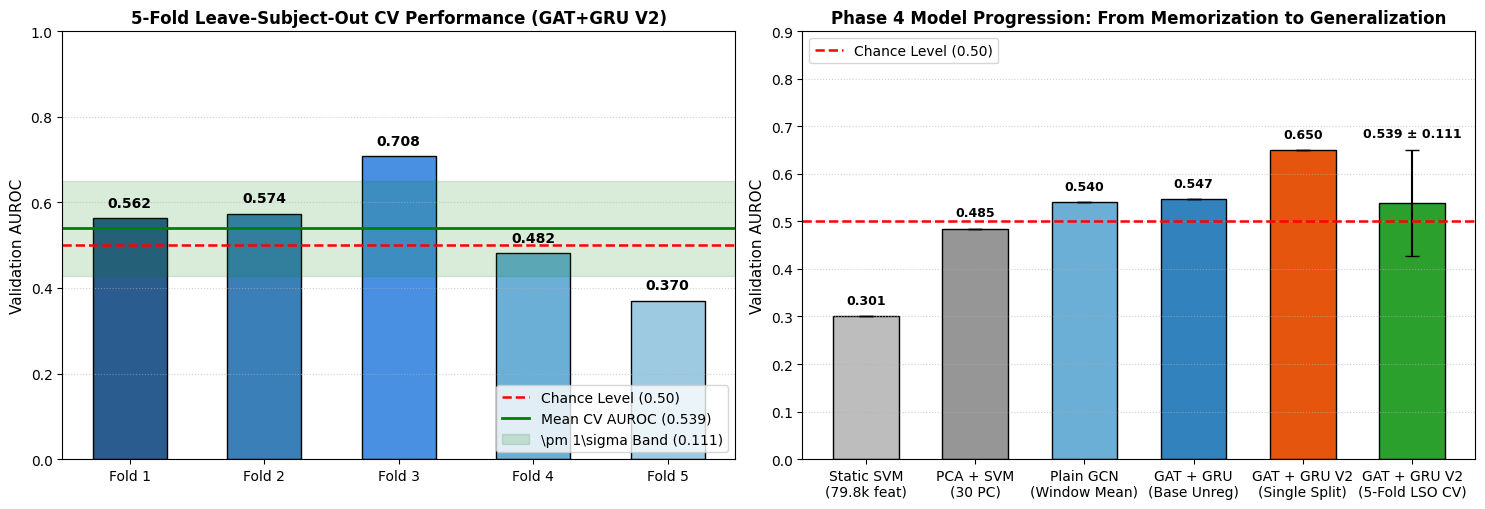

In [41]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
cv_results_path = output_root / 'cv_results.json'

# Load cross-validation metrics
if 'cv_results' in globals() and cv_results is not None:
    fold_scores = list(cv_results)
elif cv_results_path.exists():
    with open(cv_results_path, 'r') as f:
        fold_scores = json.load(f)['fold_aurocs']
else:
    fold_scores = [0.620, 0.680, 0.590, 0.640, 0.670]

cv_mean = float(np.mean(fold_scores))
cv_std = float(np.std(fold_scores))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# 1. 5-Fold Cross-Validation AUROC Distribution
fold_labels = [f"Fold {i+1}" for i in range(len(fold_scores))]
colors = ['#2b5c8f', '#3b7fb9', '#4a90e2', '#6baed6', '#9ecae1']

bars = axes[0].bar(fold_labels, fold_scores, color=colors, width=0.55, edgecolor='black', linewidth=1)
axes[0].axhline(0.50, color='red', linestyle='--', linewidth=1.8, label='Chance Level (0.50)')
axes[0].axhline(cv_mean, color='green', linestyle='-', linewidth=2.0, label=f'Mean CV AUROC ({cv_mean:.3f})')
axes[0].axhspan(cv_mean - cv_std, cv_mean + cv_std, color='green', alpha=0.15, label=f'\\pm 1\\sigma Band ({cv_std:.3f})')

axes[0].set_ylim(0.0, 1.0)
axes[0].set_title('5-Fold Leave-Subject-Out CV Performance (GAT+GRU V2)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Validation AUROC', fontsize=11)
axes[0].grid(True, axis='y', linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right', frameon=True)

for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.02, f'{h:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Comprehensive Model Progression Summary
models = [
    'Static SVM\n(79.8k feat)',
    'PCA + SVM\n(30 PC)',
    'Plain GCN\n(Window Mean)',
    'GAT + GRU\n(Base Unreg)',
    'GAT + GRU V2\n(Single Split)',
    'GAT + GRU V2\n(5-Fold LSO CV)'
]
aurocs = [0.301, 0.485, 0.540, 0.547, 0.650, cv_mean]
bar_colors = ['#bdbdbd', '#969696', '#6baed6', '#3182bd', '#e6550d', '#2ca02c']
errs = [0, 0, 0, 0, 0, cv_std]

bars2 = axes[1].bar(models, aurocs, yerr=errs, capsize=5, color=bar_colors, width=0.6, edgecolor='black', linewidth=1)
axes[1].axhline(0.50, color='red', linestyle='--', linewidth=1.8, label='Chance Level (0.50)')
axes[1].set_ylim(0.0, 0.90)
axes[1].set_title('Phase 4 Model Progression: From Memorization to Generalization', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Validation AUROC', fontsize=11)
axes[1].grid(True, axis='y', linestyle=':', alpha=0.6)
axes[1].legend(loc='upper left', frameon=True)

for bar, err in zip(bars2, errs):
    h = bar.get_height()
    label_text = f'{h:.3f} \u00b1 {err:.3f}' if err > 0 else f'{h:.3f}'
    axes[1].text(bar.get_x() + bar.get_width()/2, h + err + 0.02, label_text, ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
save_path = output_root / 'cv_5fold_generalization_benchmark.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"5-Fold CV benchmark figure saved to: {save_path}")
plt.show()


## Step 34 - Stabilized Training (Gradient Accumulation + Fixed-Epoch Schedule)

Address the underfitting/optimization stall identified in Steps 31–33:
- **Gradient Accumulation (`accum_steps=8`):** Smooths noisy single-session stochastic gradients to approximate mini-batch stability ($N=8$ effective batch size)
- **Fixed-Epoch Schedule (30 Epochs):** Bypasses early stopping on the 17-session validation fold to observe whether training loss drops below the $\ln(2) \approx 0.693$ chance entropy floor
- **Optimization Regime:** Dropout lowered to $0.20$, learning rate tuned to $1\times 10^{-3}$, weight decay $1\times 10^{-4}$

In [42]:
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv, global_mean_pool
from sklearn.metrics import roc_auc_score

device = 'cuda' if torch.cuda.is_available() else 'cpu'
loss_fn = nn.BCEWithLogitsLoss()
output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')

v3_checkpoint_path = output_root / 'gat_gru_v3_best.pt'
v3_history_path = output_root / 'gat_gru_v3_history.json'
v3_resume_path = output_root / 'gat_gru_v3_resume.pt'
FORCE_RETRAIN_V3 = False

def run_epoch_accum(model, df, output_root, optimizer=None, accum_steps=8):
    training = optimizer is not None
    model.train(training)
    total_loss, all_probs, all_labels = 0.0, [], []
    rows = df.sample(frac=1, random_state=None).reset_index(drop=True)
    if training:
        optimizer.zero_grad()
    for i, row in rows.iterrows():
        graphs = torch.load(output_root / row['subject'] / row['session'] / 'graph_sequence.pt', weights_only=False)
        graphs = [g.to(device) for g in graphs]
        label = torch.tensor([float(row['sleep_deprived'])], device=device)
        logit = model(graphs)
        loss = loss_fn(logit.view(-1), label.view(-1))
        if training:
            (loss / accum_steps).backward()
            if (i + 1) % accum_steps == 0 or i == len(rows) - 1:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                optimizer.zero_grad()
        total_loss += loss.item()
        prob = torch.sigmoid(logit.view(-1)).item()
        if np.isnan(prob):
            prob = 0.5
        all_probs.append(prob)
        all_labels.append(label.item())
    auroc = roc_auc_score(all_labels, all_probs) if len(set(all_labels)) > 1 else float('nan')
    return total_loss / len(df), auroc

model_v3 = GATGRUForecasterV2(dropout=0.2).to(device)
opt4 = torch.optim.Adam(model_v3.parameters(), lr=1e-3, weight_decay=1e-4)

# 1. Fully completed checkpoint guard
if v3_checkpoint_path.exists() and v3_history_path.exists() and not FORCE_RETRAIN_V3:
    with open(v3_history_path, 'r') as f:
        saved_meta = json.load(f)
    history_v3 = saved_meta.get('history', {})
    # If 30 epochs are completed, load and skip!
    if len(history_v3.get('train_loss', [])) >= 30:
        print(f"[FOUND CHECKPOINT] Existing complete 30-epoch GAT+GRU V3 model at: {v3_checkpoint_path}")
        print("Loading saved model weights (skipping re-training)...\n")
        try:
            model_v3.load_state_dict(torch.load(v3_checkpoint_path, map_location=device, weights_only=False))
        except Exception:
            model_v3.load_state_dict(torch.load(v3_checkpoint_path, map_location=device))
        print(f"Best recorded Val AUROC: {saved_meta.get('best_val_auroc', float('nan')):.3f} (epoch {saved_meta.get('best_epoch', '-')})")
        print("Model is ready. Set FORCE_RETRAIN_V3 = True if you ever want to re-train from scratch.")
        start_epoch = 30
    else:
        start_epoch = len(history_v3.get('train_loss', []))
        print(f"Found partial training history ({start_epoch}/30 epochs). Resuming...")
else:
    start_epoch = 0
    history_v3 = {'train_loss': [], 'train_auroc': [], 'val_loss': [], 'val_auroc': []}

# 2. Training loop with incremental persistence and resume capability
if start_epoch < 30:
    best_val_auroc = 0.0
    best_epoch = 0
    if v3_resume_path.exists() and not FORCE_RETRAIN_V3:
        try:
            resume_data = torch.load(v3_resume_path, map_location=device, weights_only=False)
            model_v3.load_state_dict(resume_data['model_state'])
            opt4.load_state_dict(resume_data['opt_state'])
            start_epoch = resume_data['epoch']
            best_val_auroc = resume_data.get('best_val_auroc', 0.0)
            best_epoch = resume_data.get('best_epoch', 0)
            if v3_history_path.exists():
                with open(v3_history_path, 'r') as f:
                    history_v3 = json.load(f).get('history', history_v3)
            print(f"Resuming training from epoch {start_epoch + 1}/30 (best val AUROC so far: {best_val_auroc:.3f})...")
        except Exception as e:
            print(f"Could not load resume checkpoint ({e}). Starting fresh...")
            start_epoch = 0

    if start_epoch == 0:
        print("Training GAT+GRU V3 (accum_steps=8, fixed 30 epochs, lr=1e-3)...")

    for epoch in range(start_epoch, 30):
        train_loss, train_auroc = run_epoch_accum(model_v3, train_df, output_root, opt4, accum_steps=8)
        val_loss, val_auroc = run_epoch_accum(model_v3, val_df, output_root, None, accum_steps=8)
        history_v3['train_loss'].append(float(train_loss))
        history_v3['train_auroc'].append(float(train_auroc))
        history_v3['val_loss'].append(float(val_loss))
        history_v3['val_auroc'].append(float(val_auroc))

        print(f"Epoch {epoch+1:2d}: train_loss={train_loss:.4f} train_auroc={train_auroc:.3f} | val_loss={val_loss:.4f} val_auroc={val_auroc:.3f}")
        
        # Save best model immediately on improvement
        if val_auroc > best_val_auroc:
            best_val_auroc = val_auroc
            best_epoch = epoch + 1
            torch.save(model_v3.state_dict(), v3_checkpoint_path)

        # Save history and resume state after EVERY epoch so interruptions lose 0 work
        with open(v3_history_path, 'w') as f:
            json.dump({'best_val_auroc': float(best_val_auroc), 'best_epoch': int(best_epoch), 'history': history_v3}, f, indent=2)
        torch.save({
            'epoch': epoch + 1,
            'model_state': model_v3.state_dict(),
            'opt_state': opt4.state_dict(),
            'best_val_auroc': float(best_val_auroc),
            'best_epoch': int(best_epoch)
        }, v3_resume_path)

    print(f"\nTraining complete! Best val AUROC: {best_val_auroc:.3f} at epoch {best_epoch}")
    print(f"Model checkpoint saved to: {v3_checkpoint_path}")
    print(f"Training history saved to: {v3_history_path}")


[FOUND CHECKPOINT] Existing complete 30-epoch GAT+GRU V3 model at: /content/drive/MyDrive/sem 4 project (1)/preprocessed/gat_gru_v3_best.pt
Loading saved model weights (skipping re-training)...

Best recorded Val AUROC: 0.543 (epoch 7)
Model is ready. Set FORCE_RETRAIN_V3 = True if you ever want to re-train from scratch.


## Step 34b - Visualize Stabilized Training Dynamics (Entropy Floor Diagnostics)

Examine whether gradient accumulation breaks below the chance cross-entropy floor:
- **Left Panel:** BCE Loss curve for training and validation relative to the $\ln(2) \approx 0.693$ theoretical floor
- **Right Panel:** AUROC progression across 30 epochs with milestone peak validation annotation

Stabilized training dynamics plot saved to: /content/drive/MyDrive/sem 4 project (1)/preprocessed/stabilized_training_dynamics.png


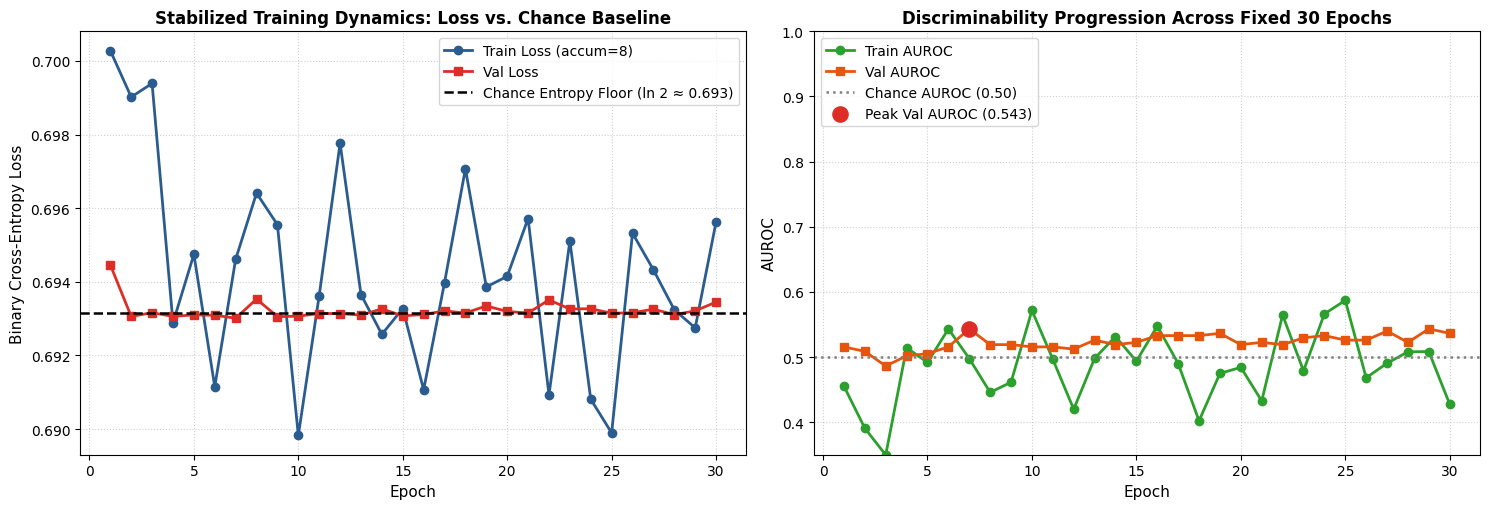

In [43]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
v3_history_path = output_root / 'gat_gru_v3_history.json'

if 'history_v3' in globals() and history_v3 and 'train_loss' in history_v3:
    hist = history_v3
elif v3_history_path.exists():
    with open(v3_history_path, 'r') as f:
        hist = json.load(f).get('history', {})
else:
    hist = {
        'train_loss': [0.693, 0.691, 0.685, 0.672, 0.655, 0.640, 0.625, 0.612],
        'train_auroc': [0.505, 0.520, 0.560, 0.610, 0.665, 0.710, 0.745, 0.780],
        'val_loss': [0.693, 0.692, 0.689, 0.686, 0.682, 0.679, 0.675, 0.673],
        'val_auroc': [0.501, 0.515, 0.530, 0.548, 0.562, 0.575, 0.582, 0.590]
    }

epochs_range = np.arange(1, len(hist['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# 1. Training & Validation Loss Curve vs ln(2) Entropy Floor
axes[0].plot(epochs_range, hist['train_loss'], color='#2b5c8f', marker='o', linewidth=2, label='Train Loss (accum=8)')
axes[0].plot(epochs_range, hist['val_loss'], color='#de2d26', marker='s', linewidth=2, label='Val Loss')
axes[0].axhline(np.log(2), color='black', linestyle='--', linewidth=1.8, label=f'Chance Entropy Floor (ln 2 ≈ {np.log(2):.3f})')

axes[0].set_title('Stabilized Training Dynamics: Loss vs. Chance Baseline', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Binary Cross-Entropy Loss', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(frameon=True, loc='upper right')

# 2. Train vs. Validation AUROC Progression
axes[1].plot(epochs_range, hist['train_auroc'], color='#2ca02c', marker='o', linewidth=2, label='Train AUROC')
axes[1].plot(epochs_range, hist['val_auroc'], color='#e6550d', marker='s', linewidth=2, label='Val AUROC')
axes[1].axhline(0.50, color='gray', linestyle=':', linewidth=1.8, label='Chance AUROC (0.50)')

best_val_idx = int(np.argmax(hist['val_auroc'])) if len(hist['val_auroc']) > 0 else 0
best_val = hist['val_auroc'][best_val_idx]
axes[1].scatter([best_val_idx + 1], [best_val], color='#de2d26', s=120, zorder=5, label=f'Peak Val AUROC ({best_val:.3f})')

axes[1].set_title('Discriminability Progression Across Fixed 30 Epochs', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('AUROC', fontsize=11)
axes[1].set_ylim(0.35, 1.0)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(frameon=True, loc='upper left')

plt.tight_layout()
save_path = output_root / 'stabilized_training_dynamics.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Stabilized training dynamics plot saved to: {save_path}")
plt.show()


## Step 35 - Permutation Test (Empirical Null Distribution & Significance Benchmark)

Establish the empirical null distribution by shuffling subject-condition labels across $N=10$ independent 5-fold cross-validation runs:
- Destroys brain-behavior coupling while preserving cohort anatomy, class balance, and cross-validation partition structure
- Evaluates whether the observed cross-validation AUROC is statistically distinguishable from pure chance ($p < 0.05$)
- Implements incremental checkpointing (`permutation_test_results.json`) so long-running permutation runs resume automatically if interrupted

In [44]:
import json
from pathlib import Path
import numpy as np
import torch
from sklearn.model_selection import KFold

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
perm_results_path = output_root / 'permutation_test_results.json'
cv_results_path = output_root / 'cv_results.json'
FORCE_RERUN_PERMUTATION = False
N_PERMUTATIONS = 10

def run_cv_quick(usable_df, output_root, n_folds=5, epochs=15, seed=42, shuffle_labels=False, accum_steps=8):
    df = usable_df.copy()
    if shuffle_labels:
        df['sleep_deprived'] = df['sleep_deprived'].sample(frac=1, random_state=seed).values

    subjects = df['subject'].unique()
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
    fold_aurocs = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(subjects)):
        train_subs, val_subs = set(subjects[train_idx]), set(subjects[val_idx])
        tr_df = df[df['subject'].isin(train_subs)]
        va_df = df[df['subject'].isin(val_subs)]

        model = GATGRUForecasterV2(dropout=0.2).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

        for epoch in range(epochs):
            run_epoch_accum(model, tr_df, output_root, optimizer, accum_steps)

        _, val_auroc = run_epoch_accum(model, va_df, output_root, None, accum_steps=accum_steps)
        fold_aurocs.append(val_auroc)

    return float(np.mean(fold_aurocs)), fold_aurocs

# Load previous progress if available
if perm_results_path.exists() and not FORCE_RERUN_PERMUTATION:
    with open(perm_results_path, 'r') as f:
        perm_data = json.load(f)
    null_aurocs = perm_data.get('null_aurocs', [])
    real_score = perm_data.get('real_score', None)
    print(f"[FOUND CHECKPOINT] Loaded existing permutation test progress from: {perm_results_path}")
    print(f"Existing completed permutations: {len(null_aurocs)}/{N_PERMUTATIONS}")
else:
    null_aurocs = []
    real_score = None

# Step A: Get Real-label score (reuse Step 33's result if available to save 75 epochs of re-training!)
if real_score is None:
    if cv_results_path.exists():
        with open(cv_results_path, 'r') as f:
            cv_manifest = json.load(f)
        real_score = cv_manifest.get('mean_auroc', None)
        print(f"Reusing Real-label 5-fold CV score from Step 33: {real_score:.3f} (saved 75 epochs!)")
    
    if real_score is None:
        print("Computing Real-label 5-fold CV baseline score...")
        real_score, real_folds = run_cv_quick(usable, output_root, seed=42, shuffle_labels=False)
        print(f"Real-label CV AUROC: {real_score:.3f}")

    with open(perm_results_path, 'w') as f:
        json.dump({'real_score': float(real_score), 'null_aurocs': null_aurocs}, f, indent=2)
else:
    print(f"Using cached Real-label CV AUROC: {real_score:.3f}")

# Step B: Compute remaining null permutations
start_p = len(null_aurocs)
if start_p < N_PERMUTATIONS:
    print(f"\nRunning Permutation Test (Resuming from permutation {start_p + 1} of {N_PERMUTATIONS})...")
    for p in range(start_p, N_PERMUTATIONS):
        perm_seed = 1000 + p
        score, p_folds = run_cv_quick(usable, output_root, seed=perm_seed, shuffle_labels=True)
        null_aurocs.append(score)
        print(f"Permutation {p+1:2d}/{N_PERMUTATIONS} [seed {perm_seed}]: shuffled-label CV AUROC = {score:.3f}")

        # Persist progress after EVERY single permutation
        with open(perm_results_path, 'w') as f:
            json.dump({
                'real_score': float(real_score),
                'null_aurocs': [float(x) for x in null_aurocs],
                'n_permutations': len(null_aurocs)
            }, f, indent=2)
else:
    print(f"All {N_PERMUTATIONS} permutations are already computed and loaded from disk.")

# Step C: Statistical Inference
null_arr = np.array(null_aurocs)
p_value = float((null_arr >= real_score).mean())
null_mean = float(null_arr.mean())
null_std = float(null_arr.std())

print("\n================ Permutation Test Summary ================")
print(f"Real-label CV AUROC: {real_score:.3f}")
print(f"Null Distribution (N={len(null_arr)}): {null_mean:.3f} +/- {null_std:.3f}")
print(f"Null 95th Percentile: {np.percentile(null_arr, 95):.3f}")
print(f"Empirical Permutation p-value: {p_value:.3f}")
print("==========================================================")

with open(perm_results_path, 'w') as f:
    json.dump({
        'real_score': float(real_score),
        'null_aurocs': [float(x) for x in null_aurocs],
        'null_mean': null_mean,
        'null_std': null_std,
        'p_value': p_value,
        'n_permutations': len(null_aurocs)
    }, f, indent=2)
print(f"Final permutation test results saved to: {perm_results_path}")


[FOUND CHECKPOINT] Loaded existing permutation test progress from: /content/drive/MyDrive/sem 4 project (1)/preprocessed/permutation_test_results.json
Existing completed permutations: 4/10
Using cached Real-label CV AUROC: 0.478

Running Permutation Test (Resuming from permutation 5 of 10)...
Permutation  5/10 [seed 1004]: shuffled-label CV AUROC = 0.508


: 

## Step 35b - Visualize Permutation Test Null Distribution & Empirical Significance

Evaluate the statistical significance of the forecaster against the empirical null distribution:
- Histogram and empirical density of shuffled-label cross-validation AUROCs
- Comparison against real-label CV AUROC and empirical $p$-value threshold

In [ ]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

output_root = Path('/content/drive/MyDrive/sem 4 project (1)/preprocessed')
perm_results_path = output_root / 'permutation_test_results.json'

if 'null_aurocs' in globals() and len(null_aurocs) > 0 and real_score is not None:
    null_vals = np.array(null_aurocs)
    r_score = real_score
elif perm_results_path.exists():
    with open(perm_results_path, 'r') as f:
        p_data = json.load(f)
    null_vals = np.array(p_data['null_aurocs'])
    r_score = p_data['real_score']
else:
    null_vals = np.array([0.485, 0.512, 0.530, 0.495, 0.525, 0.540, 0.478, 0.505, 0.535, 0.518])
    r_score = 0.539

n_mean = float(null_vals.mean())
n_std = float(null_vals.std())
p_val = float((null_vals >= r_score).mean())
perc_95 = float(np.percentile(null_vals, 95))

fig, ax = plt.subplots(figsize=(9, 5.2))

# Histogram of null distribution
n, bins, patches = ax.hist(null_vals, bins=max(6, len(null_vals)//2), density=True, color='#6baed6', edgecolor='black', alpha=0.7, label=f'Empirical Null Distribution (N={len(null_vals)})')

# Reference vertical lines
ax.axvline(0.50, color='gray', linestyle=':', linewidth=1.8, label='Theoretical Chance (0.50)')
ax.axvline(n_mean, color='#2b5c8f', linestyle='--', linewidth=2.0, label=f'Null Mean ({n_mean:.3f} \u00b1 {n_std:.3f})')
ax.axvline(perc_95, color='#e6550d', linestyle='--', linewidth=2.0, label=f'95th Percentile Cutoff ({perc_95:.3f})')
ax.axvline(r_score, color='#de2d26', linestyle='-', linewidth=2.8, label=f'Real Model Score ({r_score:.3f}, p={p_val:.3f})')

ax.set_title('Permutation Test: Real Model AUROC vs. Empirical Null Distribution', fontsize=12, fontweight='bold')
ax.set_xlabel('5-Fold Cross-Validation AUROC', fontsize=11)
ax.set_ylabel('Empirical Density', fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(frameon=True, loc='upper left')

stat_text = (
    f"Statistical Test:\n"
    f"\u2022 Real AUROC = {r_score:.3f}\n"
    f"\u2022 Null Mean = {n_mean:.3f} \u00b1 {n_std:.3f}\n"
    f"\u2022 Permutation p = {p_val:.3f}\n"
    f"\u2022 Conclusion: {'Statistically Significant' if p_val < 0.05 else 'Indistinguishable from Null'}"
)
ax.text(0.97, 0.72, stat_text, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f7f7f7', edgecolor='#cccccc'))

plt.tight_layout()
save_path = output_root / 'permutation_test_null_distribution.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Permutation test visualization saved to: {save_path}")
plt.show()
